# 27 Oct — A Gaussian mirror dent, Zernike modes, and the image

**Question:** how does a small depression on a mirror affect an image, and how faithfully can a finite set of Zernike coefficients reproduce that effect?

This notebook follows Chapter 7 of the local aberration-budget textbook. It compares **ideal optics**, **the known Gaussian dent propagated directly**, and **the wavefront reconstructed from fitted coefficients and then propagated**. It includes saved results, an order-convergence study, clearly labelled parameters, and live controls.

**Start here:** run all cells in order. Change the parameter cell **C02** for a reproducible study; use **C15** for button-driven exploration. The mathematical model is included in the notebook. Long plotting/helper cells are initially collapsed. A Python kernel with NumPy, SciPy, Matplotlib, pandas and ipywidgets is required; live controls require an active kernel and a widget-enabled Jupyter/VS Code frontend.

The three scientific outputs are: (1) the actual imaging effect in **C08–C11**; (2) the Zernike decomposition in **C09**; (3) reconstruction accuracy in wavefront and image space in **C08, C10–C12**. Saved exports are made in **C16**.


## M01 — Physical setup and the meaning of “actual”

Use an otherwise ideal focusing mirror/relay with a circular exit pupil. The mirror's **departure from its ideal figure** is mapped to that pupil with unit magnification. We factor out ideal focusing phase and propagate the residual wavefront. “Actual” below means the **known simulated truth**, not a measured commercial mirror or a full optical prescription.

**“Ideal” means this same optical system with the Gaussian dent removed ($d=0$).** It retains the same wavelength, aperture/obscuration, illumination and chosen added defocus. It is still a diffraction image, not the sharp input object. If you choose a nonzero defocus, the dent-free comparison includes that defocus too.

The model is monochromatic, scalar and paraxial. Reflectivity is spatially uniform: the dent changes phase but does not remove light. The point-spread function (PSF) comes from diffraction. Extended-object images use **spatially incoherent** intensity convolution. Coatings, polarization changes, vignetting, roughness scattering and field variation are outside this model.

At normal incidence a 3 nm deep dent produces 6 nm of peak optical path difference (OPD). “Small” geometrically does not imply small phase: phase depends on OPD divided by wavelength. Oblique incidence is an optional sensitivity parameter; only its cosine path factor is included, with a fixed mapped pupil and no projected-footprint calculation.


In [1]:
# C01 — Imports, parameter types and input checks. Run once after starting the kernel.
from __future__ import annotations
from dataclasses import dataclass, replace, asdict
from functools import lru_cache
from pathlib import Path
import json, hashlib, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from scipy.special import eval_jacobi, eval_legendre, j1
from scipy import linalg, signal, integrate

plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11,
                     'figure.dpi': 115, 'savefig.dpi': 180,
                     'axes.spines.top': False, 'axes.spines.right': False})

@dataclass(frozen=True)
class Parameters:
    # Physical lengths have explicit units. Positive depth means a depression.
    wavelength_nm: float = 13.5
    mirror_diameter_mm: float = 20.0
    focal_length_mm: float = 200.0
    incidence_deg: float = 0.0  # measured from the surface normal
    depth_nm: float = 3.0
    area_fraction: float = 0.10  # nominal area INSIDE the 1/e depth contour
    center_u: float = 0.0      # offsets in pupil-radius units
    center_v: float = 0.0
    aspect_ratio: float = 1.0  # sigma_major/sigma_minor; preserves nominal area
    orientation_deg: float = 0.0
    # Advanced support/illumination settings; keep defaults for Chapter 7's disk.
    obscuration_ratio: float = 0.0  # inner radius / outer pupil radius
    edge_amplitude: float = 1.0    # A(rho)=edge_amplitude**rho**2
    # Wavefront fit; n_max is RADIAL DEGREE, not a Noll/Fringe index.
    n_max: int = 8
    fit_family: str = 'all'         # 'all' or deliberately restrict to 'axisymmetric'
    noise_rms_nm: float = 0.0       # synthetic OPD measurement noise at fit nodes
    seed: int = 27
    added_defocus_nm: float = 0.0  # common coefficient multiplying Z_2^0 in imaging
    # Numerical sampling: fit quadrature and image grid are independent.
    n_pupil: int = 256
    fft_pad: int = 4
    quad_radial: int = 64
    quad_angular: int = 128
    # Display and test-object settings, in s = NA*x/lambda0 coordinates.
    psf_half_width_s: float = 5.0
    psf_log_floor: float = 1e-5
    scene_half_width_s: float = 7.0
    scene_kind: str = 'mixed'       # 'mixed', 'two_points', or 'bars'
    point_flux_s2: float = 0.2       # each point's integrated intensity in s-coordinate area
    point_separation_s: float = 1.0
    bar_width_s: float = 0.50
    bar_gap_s: float = 0.50

    @property
    def radius_mm(self): return self.mirror_diameter_mm/2
    @property
    def numerical_aperture(self): return self.radius_mm/self.focal_length_mm
    @property
    def image_unit_nm(self): return self.wavelength_nm/self.numerical_aperture
    @property
    def sigma_major(self): return np.sqrt(self.area_fraction*self.aspect_ratio/2)
    @property
    def sigma_minor(self): return np.sqrt(self.area_fraction/(2*self.aspect_ratio))


def validate_parameters(p):
    numeric = [v for v in asdict(p).values() if isinstance(v, (int,float))]
    if not np.all(np.isfinite(numeric)): raise ValueError('All numeric parameters must be finite.')
    if p.wavelength_nm <= 0 or p.mirror_diameter_mm <= 0 or p.focal_length_mm <= 0:
        raise ValueError('Wavelength, diameter and focal length must be positive.')
    if p.numerical_aperture > 0.2: raise ValueError('This paraxial model requires NA <= 0.2.')
    if not 0 <= p.incidence_deg <= 30: raise ValueError('Use 0 <= incidence_deg <= 30; footprint mapping is idealized.')
    if not .005 <= p.area_fraction <= .8: raise ValueError('Use .005 <= area_fraction <= .8; increase sampling for smaller dents.')
    if not 1 <= p.aspect_ratio <= 4: raise ValueError('Use 1 <= aspect_ratio <= 4.')
    if np.hypot(p.center_u,p.center_v) > 1: raise ValueError('Dent centre must lie inside or on the pupil.')
    if not 0 <= p.obscuration_ratio <= .6: raise ValueError('Use 0 <= obscuration_ratio <= .6.')
    if not .05 <= p.edge_amplitude <= 1: raise ValueError('Use .05 <= edge_amplitude <= 1.')
    if type(p.n_max) is not int or not 0 <= p.n_max <= 24: raise ValueError('n_max must be an integer from 0 to 24.')
    if p.fit_family not in ('all','axisymmetric'): raise ValueError('Unknown fit_family.')
    if p.noise_rms_nm < 0: raise ValueError('noise_rms_nm must be nonnegative.')
    if type(p.n_pupil) is not int or p.n_pupil < 64 or p.n_pupil > 512 or p.n_pupil%2:
        raise ValueError('n_pupil must be an even integer from 64 to 512.')
    if type(p.fft_pad) is not int or not 2 <= p.fft_pad <= 8 or p.n_pupil*p.fft_pad > 3072:
        raise ValueError('Use integer fft_pad from 2 to 8 and FFT side <= 3072.')
    if p.quad_radial < p.n_max+4 or p.quad_angular < 2*p.n_max+3:
        raise ValueError('Increase quadrature: radial >= n_max+4, angular >= 2*n_max+3.')
    if p.scene_kind not in ('mixed','two_points','bars'): raise ValueError('Unknown scene_kind.')
    if min(p.psf_half_width_s,p.scene_half_width_s,p.point_flux_s2,p.point_separation_s,p.bar_width_s,p.bar_gap_s) <= 0:
        raise ValueError('View and object dimensions must be positive.')
    if max(p.psf_half_width_s,p.scene_half_width_s) >= p.n_pupil/4:
        raise ValueError('Requested view must fit inside the FFT field.')
    if not 0 < p.psf_log_floor < 1: raise ValueError('psf_log_floor must lie between 0 and 1.')
    # Estimate the largest Gaussian surface slope; mm -> nm factor is explicit.
    slope = abs(p.depth_nm)*np.exp(-.5)/(p.sigma_minor*p.radius_mm*1e6)
    if slope > .01: warnings.warn('Large surface slopes: the phase-screen model needs review.')
    if p.incidence_deg > 10: warnings.warn('Only the cos(i) phase factor is included; no oblique footprint/vector model.')
    return p

from IPython.display import display, Markdown
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
_here=Path.cwd()
_candidate=_here/'Discussion Series'/'27 Oct'
PROJECT_DIR=_here if (_here/'mirror_dent_zernike.ipynb').exists() else (_candidate if _candidate.exists() else _here)
RESULTS_DIR=PROJECT_DIR/'results'
CHECKS_DIR=PROJECT_DIR/'checks'
CHECKS_DIR.mkdir(parents=True,exist_ok=True)
print('Outputs will be saved under:',PROJECT_DIR)


Outputs will be saved under: C:\Users\fxl04\Desktop\Prof. Wong Grp Papers\Discussion Series\27 Oct


## M02 — Parameters you can modify

Edit **C02**, then rerun **C07 onward**. Helper definitions C03–C06 need rerunning only if you edit their code. For a separate case, use <code>replace(P, parameter_name=new_value)</code>.

| Parameter | Units / default | What it controls |
|---|---|---|
| <code>wavelength_nm</code> | nm / 13.5 | Phase sensitivity and physical image scale. Try 550 nm with the same surface. |
| <code>mirror_diameter_mm, focal_length_mm</code> | mm / 20, 200 | Pupil radius, NA and image scale; NA must remain ≤ 0.2 here. |
| <code>incidence_deg</code> | degrees from normal / 0 | Factor $2\cos i$; keep 0 for the simplest geometry. |
| <code>depth_nm</code> | nm / +3 | Positive = depression, negative = bump, zero = ideal. Not OPD. |
| <code>area_fraction</code> | fraction / 0.10 | Nominal area inside the **1/e depth contour**, divided by full mirror area. Tails extend beyond it. |
| <code>center_u, center_v</code> | pupil-radius units / 0, 0 | Dent position; a shifted dent breaks rotational symmetry. |
| <code>aspect_ratio, orientation_deg</code> | dimensionless, degrees / 1, 0 | Elliptical Gaussian and orientation; nominal contour area is preserved. |
| <code>obscuration_ratio</code> | radius fraction / 0 | Optional central obstruction; nonzero values require a masked-pupil least-squares fit. |
| <code>edge_amplitude</code> | amplitude / 1 | Smooth illumination $A=e_{\rm edge}^{\rho^2}$; changes diffraction, not the area-fitting metric. |
| <code>n_max</code> | radial degree / 8 | Every allowed mode through this degree, including piston. **Not a single-index mode number.** |
| <code>fit_family</code> | all / default | All modes, or deliberately restrict to axisymmetric. A restriction can miss shifted/elliptical dents. |
| <code>noise_rms_nm, seed</code> | nm OPD / 0, 27 | Independent synthetic wavefront measurement noise at fit nodes; not photon noise. Seed makes it repeatable. |
| <code>added_defocus_nm</code> | nm OPD / 0 | Additional coefficient of normalized $Z_2^0$, applied **equally** to true and reconstructed pupils. |
| <code>n_pupil</code> | even pixel count / 256 | Samples across pupil diameter: resolution of surface and phase. |
| <code>fft_pad</code> | integer / 4 | Finer image-plane sampling by zero padding; **no additional pupil information**. |
| <code>quad_radial, quad_angular</code> | nodes / 64, 128 | Independent disk quadrature for fitting; increase to check integration accuracy. |
| <code>psf_half_width_s, psf_log_floor</code> | image units, intensity / 5, $10^{-5}$ | Display window and log floor. Metrics use full arrays. |
| <code>scene_kind</code> | mixed / default | mixed, two_points, or bars. Edit the object function in C05 for another object. |
| <code>scene_half_width_s</code> | image units / 7 | Object/image field of view; outside the array the object is zero. |
| <code>point_separation_s, point_flux_s2</code> | image units, integrated intensity / 1, 0.2 | Separation and per-point flux of the incoherent pair. |
| <code>bar_width_s, bar_gap_s</code> | image units / 0.5, 0.5 | Width and clear gap of three test bars; bar intensity is one arbitrary unit. |

Image coordinates are $s=\mathrm{NA}\,x/\lambda_0$; multiply by <code>P.image_unit_nm</code> to obtain image-plane nm. Default fits use a uniformly weighted clear geometric disk. Obscuration changes the fit support; amplitude apodization does not silently change the fit weights.


In [2]:
# C02 — EDIT THIS CELL for a reproducible baseline. Length units are explicit.
P = Parameters(
    wavelength_nm=13.5,
    mirror_diameter_mm=20.0,
    focal_length_mm=200.0,
    incidence_deg=0.0,
    depth_nm=3.0,
    area_fraction=0.10,
    center_u=0.0,
    center_v=0.0,
    aspect_ratio=1.0,
    orientation_deg=0.0,
    obscuration_ratio=0.0,
    edge_amplitude=1.0,
    n_max=8,
    fit_family='all',
    noise_rms_nm=0.0,
    seed=27,
    added_defocus_nm=0.0,
    n_pupil=256,
    fft_pad=4,
    quad_radial=64,
    quad_angular=128,
    psf_half_width_s=5.0,
    psf_log_floor=1e-5,
    scene_half_width_s=7.0,
    scene_kind='mixed',
    point_flux_s2=0.2,
    point_separation_s=1.0,
    bar_width_s=0.50,
    bar_gap_s=0.50,
)
CONVERGENCE_ORDERS = [0, 2, 4, 6, 8, 10, 12, 16, 20]  # EDIT the order sweep here.
EXPORT_FILES = True  # C16 saves baseline figures, coefficients, arrays and provenance.
validate_parameters(P)
display(pd.DataFrame([asdict(P)]).T.rename(columns={0:'Value'}))


,Value
wavelength_nm,13.5
mirror_diameter_mm,20.0
focal_length_mm,200.0
incidence_deg,0.0
depth_nm,3.0
area_fraction,0.1
center_u,0.0
center_v,0.0
aspect_ratio,1.0
orientation_deg,0.0


## M03 — Zernike convention and coefficient recovery

Coordinates are $u=\rho\cos\theta$, $v=\rho\sin\theta$, with $0\le\rho\le1$. Use the textbook's real, unit-mean-square convention:

$$Z_n^m=N_{nm}\,\rho^{|m|}P_{(n-|m|)/2}^{(0,|m|)}(2\rho^2-1)\,T_m(\theta).$$

Here $T_0=1$, $T_m=\cos(m\theta)$ for $m>0$, and $T_m=\sin(|m|\theta)$ for $m<0$; $N_{n0}=\sqrt{n+1}$ and $N_{nm}=\sqrt{2(n+1)}$ when $m\ne0$. Allowed indices satisfy $|m|\le n$ and $n-|m|$ even. For $m=0$, the radial factor is a shifted Legendre polynomial.

For a clear disk,

$$\langle fg\rangle=\frac1\pi\int_0^{2\pi}\int_0^1fg\,\rho\,d\rho\,d\theta,
\qquad c_n^m=\langle WZ_n^m\rangle,
\qquad \widehat W_N=\sum_{n\le N,m}c_n^mZ_n^m.$$

Coefficients are **OPD in nm**, not mirror height. Stable Jacobi evaluation avoids high-degree factorial subtraction. Fitting quadrature uses $q=\rho^2$, for which area weighting is uniform in $q$; it is independent of the Cartesian imaging grid.

With an obstruction, the admitted-pupil Gram matrix is no longer the identity. The code minimizes $\sum_\ell w_\ell(W_\ell-\sum_j B_{\ell j}c_j)^2$ using pivoted QR. Disk-normalized coefficients on that mask cannot automatically be squared and summed to obtain its RMS. Fit weights are geometric area weights; illumination amplitude enters diffraction separately.


In [3]:
# C03 — Zernike definitions, mode names, and area-weighted statistics.
def mode_list(n_max, family='all'):
    return [(n,m) for n in range(n_max+1) for m in range(-n,n+1,2)
            if family=='all' or m==0]


def zernike(n,m,u,v):
    """Real, unit-mean-square FULL-DISK modes; m>0 cosine, m<0 sine."""
    M=abs(m)
    if n < 0 or M > n or (n-M)%2: raise ValueError('Invalid (n,m).')
    rho=np.hypot(u,v); theta=np.arctan2(v,u)
    radial=rho**M*eval_jacobi((n-M)//2,0,M,2*rho*rho-1)
    if m==0: return np.sqrt(n+1)*radial
    angular=np.cos(M*theta) if m>0 else np.sin(M*theta)
    return np.sqrt(2*(n+1))*radial*angular


def mode_name(n,m):
    if (n,m)==(0,0): return 'Piston'
    if n==1: return ('x' if m>0 else 'y')+' tilt'
    if (n,m)==(2,0): return 'Defocus'
    if n==2 and abs(m)==2: return 'Primary astigmatism'
    if n==3 and abs(m)==1: return 'Balanced coma'
    if n==3 and abs(m)==3: return 'Trefoil'
    if (n,m)==(4,0): return 'Balanced primary spherical'
    if (n,m)==(6,0): return 'Balanced secondary spherical'
    if m==0: return 'Higher radial / spherical family'
    return 'Higher angular mode'


def weighted_mean(x,w): return float(np.dot(w,np.ravel(x)))
def weighted_rms(x,w,remove_mean=False):
    x=np.ravel(x)
    if remove_mean: x=x-weighted_mean(x,w)
    return float(np.sqrt(max(0,np.dot(w,x*x))))


## M04 — Gaussian geometry, reflection phase, and symmetry

Let height $h>0$ point toward the incident space. A depression has negative height. For a centred circular Gaussian,

$$h(\rho)=-d\exp[-\rho^2/(2\sigma^2)],\qquad
W=-2h\cos i=2d\cos i\,e^{-\rho^2/F},\qquad F=2\sigma^2.$$

A normal displacement adds reflection phase $(\mathbf k_i-\mathbf k_r)\cdot\delta\mathbf r=-2k_0h\cos i$. Thus the phase error is $2\pi W/\lambda_0$, with time convention $e^{-i\omega t}$. A constant coating-reflection phase is common to the pupil and is omitted.

At $\rho=\sqrt F$, depth is $d/e$, so the contour encloses fraction $F$ of the full mirror. For $F=0.10$, its radius is $0.3162a$, its standard deviation is $0.2236a$, and the half-depth contour encloses $F\ln2\approx6.93\%$. There is no hard Gaussian boundary. Offset or elongated contours can be clipped: the notebook reports a sampled clipped area separately. For an ellipse, $\sigma_{\rm major}\sigma_{\rm minor}=F/2$ preserves nominal contour area.

**Predict before running:** a centred circular dent and radial pupil are rotationally symmetric. Angular integration sets every $m\ne0$ coefficient to zero; allowed $m=0$ modes have even $n$. The dent contains piston, defocus, primary spherical and higher radial/spherical modes. It is generally **not a single spherical-aberration term**: expanding $e^{-\rho^2/F}$ produces infinitely many even radial powers. Narrower dents need higher degrees. An independent centred clear-disk expression is

$$c_{2k}^0=2d\cos i\sqrt{2k+1}\int_0^1 e^{-q/F}P_k(2q-1)\,dq.$$

Piston stays in the coefficient table to reconstruct original OPD, but contributes no intensity change. Only piston is removed from displayed wavefront RMS and comparison maps; tilt and defocus are retained unless explicitly adjusted.


In [4]:
# C04 — Known mirror shape, independent disk quadrature, and coefficient fitting.
def gaussian_height_nm(p,u,v):
    """Height relative to the ideal mirror: positive points toward incident space."""
    angle=np.deg2rad(p.orientation_deg)
    dx=u-p.center_u; dy=v-p.center_v
    qx=np.cos(angle)*dx+np.sin(angle)*dy
    qy=-np.sin(angle)*dx+np.cos(angle)*dy
    return -p.depth_nm*np.exp(-.5*((qx/p.sigma_major)**2+(qy/p.sigma_minor)**2))


def true_wavefront_nm(p,u,v):
    # A depression lengthens the reflected path. Constant coating phase is omitted.
    return -2*np.cos(np.deg2rad(p.incidence_deg))*gaussian_height_nm(p,u,v)


@lru_cache(maxsize=5)
def polar_basis(n_max,family,obscuration,nr,nt):
    """Gauss-Legendre in q=rho^2 and periodic angular quadrature.
    Weights sum to one over the admitted geometric pupil, independent of A.
    """
    x,wx=np.polynomial.legendre.leggauss(nr)
    q=obscuration**2+(1-obscuration**2)*(x+1)/2
    rho,theta=np.meshgrid(np.sqrt(q),2*np.pi*np.arange(nt)/nt,indexing='ij')
    u=(rho*np.cos(theta)).ravel(); v=(rho*np.sin(theta)).ravel()
    weights=np.repeat(wx/2/nt,nt)
    modes=mode_list(n_max,family)
    B=np.column_stack([zernike(n,m,u,v) for n,m in modes])
    G=B.T@(weights[:,None]*B)
    return {'u':u,'v':v,'weights':weights,'modes':modes,'B':B,'G':G}


def fit_wavefront(p):
    basis=polar_basis(p.n_max,p.fit_family,p.obscuration_ratio,p.quad_radial,p.quad_angular)
    u,v,w,B=(basis[k] for k in ('u','v','weights','B'))
    truth=true_wavefront_nm(p,u,v)
    rng=np.random.default_rng(p.seed)
    noise=rng.normal(0,p.noise_rms_nm,truth.shape)
    measured=truth+noise
    if p.obscuration_ratio==0:
        coeff=B.T@(w*measured)  # c_j=<W Z_j>; full disk area weights, NOT amplitude weights
        method='Full-disk orthogonal projection'
    else:
        rootw=np.sqrt(w)
        # QR with column pivoting; do not explicitly invert the normal equations.
        coeff,_,rank,_=linalg.lstsq(rootw[:,None]*B,rootw*measured,lapack_driver='gelsy')
        if rank < len(coeff): raise ValueError('Masked-pupil fit is rank deficient; reduce n_max.')
        method='Area-weighted least squares (pivoted QR) on admitted pupil'
    reconstructed=B@coeff
    error=truth-reconstructed
    eigenvalues=np.linalg.eigvalsh(basis['G'])
    condition=float(np.sqrt(max(eigenvalues[-1],0)/max(eigenvalues[0],np.finfo(float).tiny)))
    if condition>1e7: warnings.warn('Fit is ill conditioned; reduce n_max or obscuration.')
    return {**basis,'true_nm':truth,'measured_nm':measured,'fit_nm':reconstructed,
            'coeff_nm':coeff,'error_nm':error,'method':method,'condition_design':condition,
            'gram_error':float(np.max(abs(basis['G']-np.eye(len(coeff))))),
            'true_rms_nm':weighted_rms(truth,w,True),
            'residual_rms_nm':weighted_rms(error,w,True),
            'raw_residual_rms_nm':weighted_rms(error,w),
            'noise_realized_rms_nm':weighted_rms(noise,w,True)}


def reconstruct_wavefront(coeff,modes,u,v):
    result=np.zeros_like(u,dtype=float)
    # Ignore numerical angular roundoff at the 1e-13 relative coefficient level.
    tol=1e-13*max(float(np.max(abs(coeff))),1e-20)
    for c,(n,m) in zip(coeff,modes):
        if abs(c)>tol: result+=c*zernike(n,m,u,v)
    return result


def coefficient_table(p,fit):
    rows=[{'n':n,'m':m,'mode':mode_name(n,m),'coefficient_nm':c,
           'coefficient_waves':c/p.wavelength_nm}
          for (n,m),c in zip(fit['modes'],fit['coeff_nm'])]
    return pd.DataFrame(rows)


## M05 — From coefficients to a diffraction image

After factoring out ideal convergence, the pupil field is

$$P(u,v)=A(u,v)\exp\left[\frac{2\pi i}{\lambda_0}\big(W(u,v)+d_fZ_2^0(u,v)\big)\right].$$

At the nominal focal plane,

$$U(s_x,s_y)\propto\iint P(u,v)e^{-2\pi i(us_x+vs_y)}\,du\,dv,
\qquad I=|U|^2,\qquad s_x=\frac{\mathrm{NA}\,x}{\lambda_0}.$$

The negative Fourier kernel is the physical-pupil convention of the 20 Oct notes: positive pupil tilt gives positive image displacement. The textbook also discusses an inverse-kernel spatial-frequency convention with reversed pupil axes.

For reconstruction, replace $W$ by $\widehat W_N$, then **repeat the exponential, Fourier transform and squared modulus**. A linear sum of modal PSF intensities would be incorrect. The dent-free, true-dent and reconstructed cases all receive the same added defocus coefficient $d_f$.

Every PSF uses one common normalization: the peak of the dent-free, in-focus pupil with the same aperture and amplitude. The plotted ideal comparison is dent-free at the chosen focus, so its peak need not equal one when added defocus is nonzero. No PSF is rescaled to its own peak. <code>on_axis_ratio</code> evaluates the fixed origin; <code>sampled_peak_ratio</code> is the largest sampled value at the chosen focus, not an optimized-focus Strehl. Encircled energy uses that same origin. A phase-only defect conserves power while redistributing intensity.

For a spatially incoherent extended object,

$$I_{\rm image}=I_{\rm object}*\mathrm{PSF}_{\rm unit\ energy}.$$

The code uses zero-extended linear convolution and explicitly centres even-sized FFT kernels. It does not wrap opposite image edges together. Partially coherent mask imaging requires the appropriate source/pupil propagation model instead.


In [5]:
# C05 — Pupil, diffraction, metrics, object images, convergence and refocus.
def cartesian_pupil(p):
    du=2/p.n_pupil
    coord=(np.arange(p.n_pupil)-p.n_pupil//2)*du
    u,v=np.meshgrid(coord,coord); rho=np.hypot(u,v)
    support=(rho<=1)&(rho>=p.obscuration_ratio)
    amplitude=np.where(support,p.edge_amplitude**(rho*rho),0.)
    return u,v,support,amplitude,du


def propagate_psf(wavefront_nm,amplitude,p):
    """Negative Fourier kernel; intensity uses the SAME ideal peak normalization.
    s=NA*x/lambda0. Zero padding interpolates the FFT; it adds no pupil detail.
    """
    side=p.n_pupil*p.fft_pad; start=(side-p.n_pupil)//2
    field=amplitude*np.exp(2j*np.pi*wavefront_nm/p.wavelength_nm)
    padded=np.zeros((side,side),dtype=complex)
    padded[start:start+p.n_pupil,start:start+p.n_pupil]=field
    amp=np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(padded)))
    intensity=(amp.real**2+amp.imag**2)/amplitude.sum()**2
    s=np.fft.fftshift(np.fft.fftfreq(side,d=2/p.n_pupil))
    return s,intensity


def psf_metrics(s,I):
    center=len(s)//2
    disk=(s[:,None]**2+s[None,:]**2)<=.61**2
    return {'on_axis_ratio':float(I[center,center]),
            'sampled_peak_ratio':float(I.max()),
            'energy_in_0p61':float(I[disk].sum()/I.sum()),
            'discrete_total_intensity':float(I.sum())}


def build_study(p):
    validate_parameters(p)
    fit=fit_wavefront(p)
    u,v,support,A,du=cartesian_pupil(p)
    height=gaussian_height_nm(p,u,v)
    actual=true_wavefront_nm(p,u,v)
    reconstructed=reconstruct_wavefront(fit['coeff_nm'],fit['modes'],u,v)
    common_focus=p.added_defocus_nm*zernike(2,0,u,v)
    phase=2*np.pi*(actual+common_focus)/p.wavelength_nm
    phase_steps=[np.max(abs(np.diff(phase,axis=axis))[np.take(support,range(p.n_pupil-1),axis=axis)&np.take(support,range(1,p.n_pupil),axis=axis)]) for axis in (0,1)]
    max_phase_step=float(max(phase_steps))
    if max_phase_step>np.pi/2: warnings.warn('Large phase change per pupil pixel; increase n_pupil and check convergence.')
    if p.sigma_minor*p.n_pupil/2<5: warnings.warn('Gaussian width has fewer than five pixels; refine the pupil grid.')
    s,ideal=propagate_psf(common_focus,A,p)  # ideal comparison = dent removed, same focus
    _,truth=propagate_psf(actual+common_focus,A,p)
    _,recon=propagate_psf(reconstructed+common_focus,A,p)
    metric_rows=[]
    for label,I in [('Ideal',ideal),('True dent',truth),('Zernike reconstruction',recon)]:
        metric_rows.append({'case':label,**psf_metrics(s,I)})
    metrics=pd.DataFrame(metric_rows).set_index('case')
    relative_psf_error=float(np.linalg.norm(recon-truth)/np.linalg.norm(truth))
    # Actual clipped area: full geometric mirror, not the illuminated annular area.
    q=(u-p.center_u)*np.cos(np.deg2rad(p.orientation_deg))+(v-p.center_v)*np.sin(np.deg2rad(p.orientation_deg))
    r=-(u-p.center_u)*np.sin(np.deg2rad(p.orientation_deg))+(v-p.center_v)*np.cos(np.deg2rad(p.orientation_deg))
    inside_contour=(q/p.sigma_major)**2+(r/p.sigma_minor)**2<=2
    full_disk=(u*u+v*v)<=1
    clipped_area_fraction=float(np.count_nonzero(inside_contour&full_disk)/np.count_nonzero(full_disk))
    return {'p':p,'fit':fit,'u':u,'v':v,'support':support,'amplitude':A,
            'height_nm':height,'actual_nm':actual,'reconstructed_nm':reconstructed,
            'focus_nm':common_focus,'s':s,'ideal_psf':ideal,'true_psf':truth,'recon_psf':recon,
            'coefficients':coefficient_table(p,fit),'metrics':metrics,
            'relative_psf_error':relative_psf_error,'clipped_area_fraction':clipped_area_fraction,
            'max_phase_step_rad':max_phase_step}


def make_scene(p,ds):
    half=int(np.ceil(p.scene_half_width_s/ds))
    x=np.arange(-half,half+1)*ds; xx,yy=np.meshgrid(x,x); obj=np.zeros_like(xx)
    if p.scene_kind in ('two_points','mixed'):
        # Deposit point intensities by bilinear interpolation; preserve separation below one pixel.
        y0=2.0 if p.scene_kind=='mixed' else 0.0
        for x0 in (-p.point_separation_s/2,p.point_separation_s/2):
            fx=x0/ds+half; fy=y0/ds+half; ix=int(np.floor(fx)); iy=int(np.floor(fy))
            for dy in (0,1):
                for dx in (0,1):
                    if 0<=iy+dy<len(x) and 0<=ix+dx<len(x):
                        obj[iy+dy,ix+dx]+=p.point_flux_s2/ds**2*(1-abs(fy-(iy+dy)))*(1-abs(fx-(ix+dx)))
    if p.scene_kind in ('bars','mixed'):
        center_y=-1.5 if p.scene_kind=='mixed' else 0
        for center_x in (-1.5,0,1.5):
            # Supersample object pixels; narrow bars should not disappear by pixel coincidence.
            coverage=np.zeros_like(obj)
            for sy in (-.375,-.125,.125,.375):
                for sx in (-.375,-.125,.125,.375):
                    mask=(abs(xx+sx*ds-center_x*(p.bar_width_s+p.bar_gap_s)/1.5)<=p.bar_width_s/2)&(abs(yy+sy*ds-center_y)<=1.0)
                    coverage+=mask/16
            obj+=coverage
    return x,obj


def incoherent_image(obj,I):
    """Zero-extended linear convolution; explicitly align even-sized FFT kernels.
    PSF has unit DISCRETE sum. Object is mutually incoherent intensity.
    """
    kernel=I/I.sum()
    full=signal.fftconvolve(obj,kernel,mode='full')
    cy,cx=np.array(kernel.shape)//2
    image=full[cy:cy+obj.shape[0],cx:cx+obj.shape[1]]
    return np.maximum(image,0)  # remove floating-point negative roundoff only


def scene_images(study):
    p=study['p']; ds=study['s'][1]-study['s'][0]
    x,obj=make_scene(p,ds)
    return x,obj,{key:incoherent_image(obj,study[key+'_psf']) for key in ('ideal','true','recon')}


def convergence_study(p,orders=(0,2,4,6,8,10,12,16,20)):
    # Same noise realization and truth at each order; all fits are repeated honestly.
    base=build_study(p); rows=[]
    for nmax in sorted(set(orders)):
        q=replace(p,n_max=int(nmax))
        validate_parameters(q)
        fit=fit_wavefront(q)
        W=reconstruct_wavefront(fit['coeff_nm'],fit['modes'],base['u'],base['v'])
        _,I=propagate_psf(W+base['focus_nm'],base['amplitude'],q)
        true_var=fit['true_rms_nm']**2
        rows.append({'n_max':nmax,'mode_count':len(fit['modes']),
                     'residual_rms_nm':fit['residual_rms_nm'],
                     'residual_rms_waves':fit['residual_rms_nm']/p.wavelength_nm,
                     'variance_explained':1-fit['residual_rms_nm']**2/true_var if true_var>0 else 1.,
                     'psf_relative_L2':np.linalg.norm(I-base['true_psf'])/np.linalg.norm(base['true_psf']),
                     **psf_metrics(base['s'],I)})
    return pd.DataFrame(rows)


def area_rms_refocus_coefficient(study):
    """Additional Z_2^0 coefficient minimizing geometric-area OPD variance.
    This is NOT an optimization of peak intensity, and uses known simulated truth.
    """
    fit=study['fit']; w=fit['weights']
    z=zernike(2,0,fit['u'],fit['v']); z-=np.dot(w,z)
    W=fit['true_nm']+study['p'].added_defocus_nm*zernike(2,0,fit['u'],fit['v'])
    W=W-np.dot(w,W)
    return -float(np.dot(w,W*z)/np.dot(w,z*z))


## M06 — Plotting helpers

The collapsed cell contains plotting functions only. Maps show nm of surface height or OPD; image maps show intensity. Actual and reconstructed OPD share one scale, while the residual has its own labelled scale. PSF panels use a common ideal-peak scale. No plotting function changes a fit or refocuses the baseline.


In [6]:
# C06 — Plotting helpers; expand to modify layout, colour maps or styles.
def _finish(fig):
    fig.tight_layout()
    return fig


def _disk_map(ax,study,data,title,limit=None,cmap='RdBu_r'):
    p=study['p']; a=p.radius_mm
    masked=np.where(study['support'],data,np.nan)
    if limit is None: limit=max(float(np.nanmax(abs(masked))),1e-12)
    du=2/p.n_pupil
    extent=np.array([-1-du/2,1-du/2,-1-du/2,1-du/2])*a
    im=ax.imshow(masked,origin='lower',extent=extent,cmap=cmap,vmin=-limit,vmax=limit)
    ax.set(title=title,xlabel='Pupil x (mm)',ylabel='Pupil y (mm)')
    ax.set_aspect('equal')
    return im


def plot_geometry(study):
    p=study['p']; u,v=study['u'],study['v']
    fig=plt.figure(figsize=(14,4.2))
    ax=fig.add_subplot(131)
    im=_disk_map(ax,study,study['height_nm'],'Surface departure from ideal mirror')
    fig.colorbar(im,ax=ax,label='Height h (nm); negative = dent',shrink=.8)
    ax=fig.add_subplot(132,projection='3d')
    stride=max(1,p.n_pupil//65)
    h=np.where(study['support'],study['height_nm'],np.nan)
    ax.plot_surface(u[::stride,::stride]*p.radius_mm,v[::stride,::stride]*p.radius_mm,
                    h[::stride,::stride],cmap='viridis',linewidth=0,antialiased=True)
    ax.set(xlabel='x (mm)',ylabel='y (mm)',zlabel='h (nm)',title='Dent height: vertical scale exaggerated')
    ax.view_init(elev=28,azim=-60)
    ax=fig.add_subplot(133)
    line=np.linspace(-1,1,800)
    hline=gaussian_height_nm(p,line,np.full_like(line,p.center_v))
    Wline=true_wavefront_nm(p,line,np.full_like(line,p.center_v))
    ax.plot(line*p.radius_mm,hline,label='Surface h')
    ax.plot(line*p.radius_mm,Wline,label='Reflected OPD W = -2 h cos(i)')
    ax.axhline(0,color='.6',lw=.6)
    ax.set(xlabel='x (mm), through dent centre',ylabel='Departure (nm)',title='Surface height and wavefront are different')
    ax.legend(fontsize=8);ax.grid(alpha=.2)
    fig.suptitle('Gaussian mirror defect: nominal 1/e area = '+f'{100*p.area_fraction:.1f}% of the mirror',y=1.03)
    return _finish(fig)


def plot_wavefronts(study):
    fit=study['fit']; w=fit['weights']
    a=study['actual_nm']-np.dot(w,fit['true_nm'])
    b=study['reconstructed_nm']-np.dot(w,fit['fit_nm'])
    residual=a-b
    limit=max(float(np.max(abs(a[study['support']]))),float(np.max(abs(b[study['support']]))),1e-9)
    fig,axes=plt.subplots(1,3,figsize=(13,4.0))
    for ax,data,title,lim in zip(axes,[a,b,residual],
       ['True OPD (piston removed)','Zernike OPD (piston removed)','True minus reconstructed OPD'],
       [limit,limit,None]):
        im=_disk_map(ax,study,data,title,lim)
        fig.colorbar(im,ax=ax,label='OPD (nm)',shrink=.8)
    fig.suptitle(f'n_max={study["p"].n_max}; residual area RMS = {fit["residual_rms_nm"]:.5g} nm. Residual uses its own labelled scale.',y=1.02)
    return _finish(fig)


def plot_coefficients(study):
    table=study['coefficients']; p=study['p']
    fig,axes=plt.subplots(1,2,figsize=(13,4.1))
    nonzero=table.loc[table['coefficient_nm'].abs().sort_values(ascending=False).index].head(15)
    axes[0].bar(np.arange(len(nonzero)),nonzero.coefficient_nm,color='#177b91')
    axes[0].set_xticks(np.arange(len(nonzero)),[f'({n},{m})' for n,m in zip(nonzero.n,nonzero.m)],rotation=60)
    axes[0].set(ylabel='OPD coefficient (nm)',xlabel='(n,m), ranked by absolute coefficient',title='Largest fitted coefficients (includes piston)')
    axes[0].axhline(0,color='.3',lw=.7)
    maxc=max(float(table.coefficient_nm.abs().max()),1e-12)
    im=axes[1].scatter(table.m,table.n,c=table.coefficient_nm,cmap='RdBu_r',vmin=-maxc,vmax=maxc,s=170,edgecolors='.3',lw=.3)
    axes[1].set(xlabel='Angular index m',ylabel='Radial degree n',title='All retained modes; only m=0 survives ideal symmetry')
    fig.colorbar(im,ax=axes[1],label='OPD coefficient (nm)')
    axes[1].set_yticks(range(0,p.n_max+1,2));axes[1].grid(alpha=.2)
    return _finish(fig)


def plot_modal_contributions(study):
    coeff=study['fit']['coeff_nm']; modes=study['fit']['modes']
    ranked=np.argsort(abs(coeff))[::-1]
    valid=[i for i in ranked if abs(coeff[i])>max(abs(coeff).max()*1e-9,1e-13)][:6]
    fig,axes=plt.subplots(2,3,figsize=(12,7),constrained_layout=True)
    maps=[coeff[i]*zernike(*modes[i],study['u'],study['v']) for i in valid]
    limit=max([float(np.max(abs(a[study['support']]))) for a in maps]+[1e-12])
    for ax,i,data in zip(axes.ravel(),valid,maps):
        n,m=modes[i]
        im=_disk_map(ax,study,data,f'c Z_({n},{m}); c = {coeff[i]:+.4g} nm',limit)
    for ax in axes.ravel()[len(valid):]:ax.axis('off')
    if valid:
        fig.colorbar(im,ax=list(axes.ravel()),label='Modal OPD (nm): one shared numerical scale',shrink=.85,pad=.02)
    else:
        axes[0,0].text(.5,.5,'All retained coefficients are zero.',ha='center',transform=axes[0,0].transAxes)
    fig.suptitle('Largest individual modal contributions: sum these maps to reconstruct W.')
    return fig


def _psf_crop(study):
    p=study['p']; s=study['s']; mask=abs(s)<=p.psf_half_width_s
    return mask,s[mask]


def _ee(s,I,rmax=5):
    radii=np.hypot(s[:,None],s[None,:])
    edges=np.linspace(0,rmax,151)
    values,_=np.histogram(radii,bins=edges,weights=I)
    return edges[1:],np.cumsum(values)/I.sum()


def plot_psfs(study):
    p=study['p']; s=study['s']; mask,sc=_psf_crop(study)
    ds=s[1]-s[0]; extent=[sc[0]-ds/2,sc[-1]+ds/2,sc[0]-ds/2,sc[-1]+ds/2]
    images=[study[k+'_psf'] for k in ('ideal','true','recon')]
    titles=['Ideal: no dent','True dent: direct diffraction','From Zernike coefficients']
    fig,axes=plt.subplots(2,3,figsize=(13,8.0))
    for ax,I,title in zip(axes[0],images,titles):
        im=ax.imshow(np.maximum(I[np.ix_(mask,mask)],p.psf_log_floor),origin='lower',extent=extent,
                     cmap='magma',norm=LogNorm(p.psf_log_floor,1))
        ax.set(title=title,xlabel='s_x = NA x / wavelength',ylabel='s_y = NA y / wavelength')
        fig.colorbar(im,ax=ax,label='I / no-dent in-focus peak',shrink=.8)
    mid=len(s)//2
    colors=['#333333','#c54b31','#087e8b']
    for I,title,color in zip(images,titles,colors):
        axes[1,0].semilogy(s[mask],np.maximum(I[mid,mask],1e-14),label=title,color=color)
        rr,ee=_ee(s,I,p.psf_half_width_s);axes[1,1].plot(rr,ee,label=title,color=color)
    axes[1,0].set(xlabel='s_x at s_y=0',ylabel='I / no-dent in-focus peak',ylim=(p.psf_log_floor,1.2),title='Same normalization: no rescaling of each peak')
    axes[1,0].legend(fontsize=7);axes[1,0].grid(alpha=.2)
    axes[1,1].axvline(.61,color='.5',ls=':',lw=1)
    axes[1,1].set(xlabel='Radius s',ylabel='Fraction of total FFT-plane energy',ylim=(0,1.01),title='Encircled energy about the reference origin')
    axes[1,1].grid(alpha=.2)
    diff=(images[2]-images[1])[np.ix_(mask,mask)]
    limit=max(float(np.max(abs(diff))),1e-12)
    im=axes[1,2].imshow(diff,origin='lower',extent=extent,cmap='RdBu_r',vmin=-limit,vmax=limit)
    axes[1,2].set(xlabel='s_x',ylabel='s_y',title='Reconstructed minus true intensity')
    fig.colorbar(im,ax=axes[1,2],label='Difference / no-dent in-focus peak',shrink=.8)
    fig.suptitle(f'1 image unit = {p.image_unit_nm:.4g} nm; clear-disk Airy reference = {0.61*p.image_unit_nm:.4g} nm. PSF relative L2 error = {study["relative_psf_error"]:.4g}',y=1.02)
    return _finish(fig)


def plot_scene(study):
    p=study['p']; x,obj,images=scene_images(study); ds=x[1]-x[0]
    extent=[x[0]-ds/2,x[-1]+ds/2,x[0]-ds/2,x[-1]+ds/2]
    fig,axes=plt.subplots(2,3,figsize=(13,7.7))
    ax=axes[0,0];im=ax.imshow(np.maximum(obj,1e-3),origin='lower',extent=extent,cmap='gray',norm=LogNorm(vmin=1e-3,vmax=max(float(obj.max()),.01)))
    ax.set(title='Input object intensity (own logarithmic scale)',xlabel='s_x',ylabel='s_y')
    fig.colorbar(im,ax=ax,label='Object intensity (arbitrary units)',shrink=.75)
    vmax=max(float(I.max()) for I in images.values())
    for ax,key,title in [(axes[0,1],'ideal','Ideal: no dent'),(axes[0,2],'true','True dent: incoherent image'),(axes[1,0],'recon','Reconstructed incoherent image')]:
        im=ax.imshow(images[key],origin='lower',extent=extent,cmap='gray',vmin=0,vmax=max(vmax,1e-12))
        ax.set(title=title,xlabel='s_x',ylabel='s_y')
        fig.colorbar(im,ax=ax,label='Image intensity (common scale)',shrink=.75)
    diff=images['recon']-images['true'];limit=max(float(np.max(abs(diff))),1e-12)
    im=axes[1,1].imshow(diff,origin='lower',extent=extent,cmap='RdBu_r',vmin=-limit,vmax=limit)
    axes[1,1].set(title='Reconstructed minus true image',xlabel='s_x',ylabel='s_y')
    fig.colorbar(im,ax=axes[1,1],label='Intensity difference',shrink=.75)
    row=int(np.argmin(abs(x-(-1.5 if p.scene_kind=='mixed' else 0))))
    for key,label in [('ideal','Ideal: no dent'),('true','True dent'),('recon','Reconstructed')]:
        axes[1,2].plot(x,images[key][row],label=label)
    axes[1,2].set(xlabel='s_x',ylabel='Image intensity',title=f'Cross section at s_y={x[row]:.3g}')
    axes[1,2].legend(fontsize=8);axes[1,2].grid(alpha=.2)
    error=np.linalg.norm(diff)/max(np.linalg.norm(images['true']),1e-30)
    fig.suptitle(f'Mutually incoherent, shift-invariant imaging: I_image = I_object * unit-energy PSF. Image relative L2 error = {error:.4g}',y=1.02)
    return _finish(fig)


def plot_convergence(table,study):
    fig,axes=plt.subplots(2,2,figsize=(11,7))
    axes[0,0].semilogy(table.n_max,np.maximum(table.residual_rms_nm,1e-14),'o-')
    axes[0,0].set(ylabel='Piston-removed residual OPD RMS (nm)',title='Wavefront reconstruction')
    axes[0,1].semilogy(table.n_max,np.maximum(table.psf_relative_L2,1e-15),'o-',color='#c54b31')
    axes[0,1].set(ylabel='Relative L2 error of full PSF array',title='Imaging reconstruction')
    axes[1,0].plot(table.n_max,100*table.variance_explained,'o-')
    axes[1,0].set(ylabel='Geometric-area OPD variance explained (%)',title='Noiseless nested fits improve wavefront RMS')
    axes[1,1].plot(table.n_max,table.on_axis_ratio,'o-',label='Reconstructed on-axis ratio')
    axes[1,1].axhline(study['metrics'].loc['True dent','on_axis_ratio'],ls='--',color='#c54b31',label='True on-axis ratio')
    axes[1,1].set(ylabel='I(0) / ideal peak',title='A single image metric can converge non-monotonically')
    axes[1,1].legend(fontsize=8)
    for ax in axes.ravel():ax.set_xlabel('Maximum radial degree n_max');ax.grid(alpha=.2)
    return _finish(fig)


def plot_refocus(study):
    extra=area_rms_refocus_coefficient(study); p=study['p']
    W=study['actual_nm']+study['focus_nm']+extra*zernike(2,0,study['u'],study['v'])
    _,I=propagate_psf(W,study['amplitude'],p)
    mask,sc=_psf_crop(study);ds=study['s'][1]-study['s'][0]
    extent=[sc[0]-ds/2,sc[-1]+ds/2,sc[0]-ds/2,sc[-1]+ds/2]
    fig,axes=plt.subplots(1,3,figsize=(13,4))
    for ax,img,title in zip(axes[:2],[study['true_psf'],I],['True dent at chosen reference focus','True dent after area-RMS refocus']):
        im=ax.imshow(np.maximum(img[np.ix_(mask,mask)],p.psf_log_floor),origin='lower',extent=extent,cmap='magma',norm=LogNorm(p.psf_log_floor,1))
        ax.set(title=title,xlabel='s_x',ylabel='s_y');fig.colorbar(im,ax=ax,label='I / no-dent in-focus peak',shrink=.8)
    fit=study['fit'];w=fit['weights']
    Wq=fit['true_nm']+(p.added_defocus_nm+extra)*zernike(2,0,fit['u'],fit['v'])
    im=_disk_map(axes[2],study,W-np.dot(w,Wq),'Residual wavefront after refocus')
    fig.colorbar(im,ax=axes[2],label='OPD (nm)',shrink=.8)
    sigma=weighted_rms(Wq,w,True)
    dz_nm=-4*np.sqrt(3)*extra/p.numerical_aperture**2
    fig.suptitle(f'Added Z_2^0 coefficient = {extra:+.5g} nm; equivalent plane shift = {dz_nm:+.5g} nm; remaining RMS = {sigma:.5g} nm',y=1.05)
    return _finish(fig)


## M07 — Compute the baseline

This cell connects mirror departure → reflected OPD → area-weighted coefficients → reconstructed OPD → diffraction images. A rapid pixel-to-pixel phase change calls for a finer pupil grid, rather than only more zero padding.


In [7]:
# C07 — Run the baseline after editing C02. No noise is added by default.
BASE = build_study(P)
FIGURES = {}
f=BASE['fit']
print(f'NA = {P.numerical_aperture:.5g}; 1 image unit = {P.image_unit_nm:.5g} nm')
print(f'Gaussian sigma_major/minor = {P.sigma_major:.5g}, {P.sigma_minor:.5g} pupil radii')
print(f'Sampled 1/e contour area inside full mirror: {100*BASE["clipped_area_fraction"]:.4g}%')
print(f'Peak OPD of untruncated Gaussian = {2*P.depth_nm*np.cos(np.deg2rad(P.incidence_deg)):.5g} nm')
print(f'Mode count = {len(f["modes"])}; fit method: {f["method"]}')
print(f'True piston-removed OPD RMS = {f["true_rms_nm"]:.6g} nm')
print(f'Reconstruction residual RMS = {f["residual_rms_nm"]:.6g} nm = {f["residual_rms_nm"]/P.wavelength_nm:.6g} waves')
print(f'Gram deviation = {f["gram_error"]:.3g}; design condition number = {f["condition_design"]:.4g}')
print(f'Maximum neighbouring-pixel phase step = {BASE["max_phase_step_rad"]:.4g} rad')
print(f'Full-array PSF relative L2 error = {BASE["relative_psf_error"]:.6g}')


NA = 0.05; 1 image unit = 270 nm
Gaussian sigma_major/minor = 0.22361, 0.22361 pupil radii
Sampled 1/e contour area inside full mirror: 10.02%
Peak OPD of untruncated Gaussian = 6 nm
Mode count = 45; fit method: Full-disk orthogonal projection
True piston-removed OPD RMS = 1.20001 nm
Reconstruction residual RMS = 0.107443 nm = 0.00795871 waves
Gram deviation = 3.45e-15; design condition number = 1
Maximum neighbouring-pixel phase step = 0.05917 rad
Full-array PSF relative L2 error = 0.0102619


## M08 — The mirror and the reconstructed wavefront

The surface plot shows **departure from the ideal mirror**: nm vertically and mm laterally, with vertical scale exaggerated. The OPD comparison shows what the expansion captured before image formation. A small wavefront residual is useful evidence, but imaging must still be calculated.


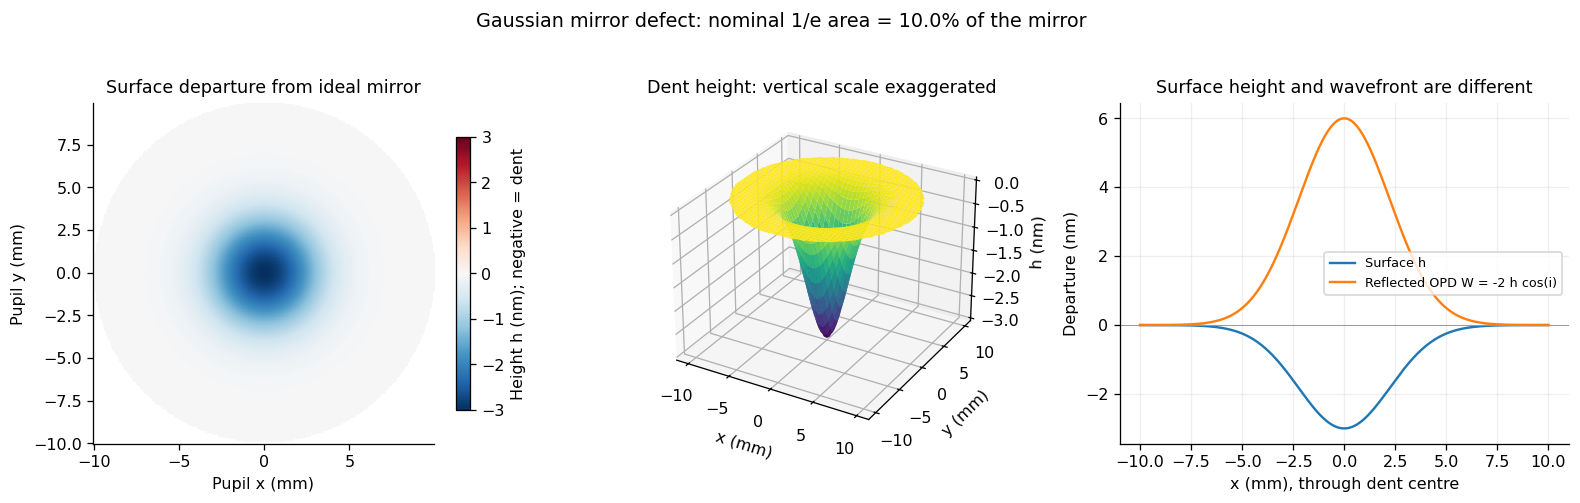

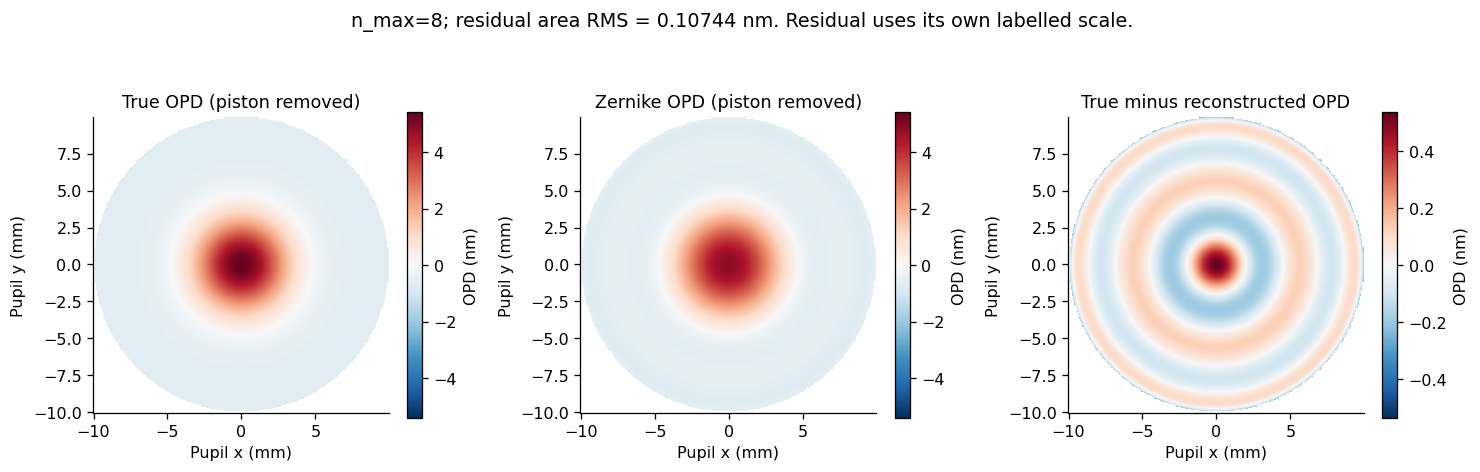

In [8]:
# C08 — Surface geometry; true, reconstructed and residual OPD maps.
FIGURES['01_mirror_geometry']=plot_geometry(BASE)
display(FIGURES['01_mirror_geometry']);plt.close(FIGURES['01_mirror_geometry'])
FIGURES['02_wavefront_reconstruction']=plot_wavefronts(BASE)
display(FIGURES['02_wavefront_reconstruction']);plt.close(FIGURES['02_wavefront_reconstruction'])


## M09 — Resolve the dent into Zernike modes

The table includes **every** retained mode. Near-zero angular coefficients in the symmetric case are quadrature roundoff, not physical coma or astigmatism. The bar plot ranks coefficient magnitude; the $(n,m)$ map retains the mode labels. Individual contribution maps show $c_n^mZ_n^m$ in nm on a common scale.

For a noiseless clear disk, squared nonpiston coefficients sum to represented variance; omitted modes carry the residual. With noise, high orders may fit noise. With an obstruction, evaluate the weighted residual rather than a naive sum of squared disk coefficients.


,n,m,mode,coefficient_nm,coefficient_waves
0,0,0,Piston,0.5999728,0.04444243
1,1,-1,y tilt,-4.498911e-19,-3.332527e-20
2,1,1,x tilt,-1.827989e-17,-1.354066e-18
3,2,-2,Primary astigmatism,-4.632614e-18,-3.431566e-19
4,2,0,Defocus,-0.831441,-0.06158822
5,2,2,Primary astigmatism,-3.714074e-18,-2.751166e-19
6,3,-3,Trefoil,5.201659e-19,3.853081e-20
7,3,-1,Balanced coma,-1.079828e-17,-7.998726e-19
8,3,1,Balanced coma,2.773438e-17,2.054399e-18
9,3,3,Trefoil,-4.422601e-18,-3.276e-19


Worked projection: c_2^0 = sum(weight * W_measured * Z_2^0) = -0.831441 nm


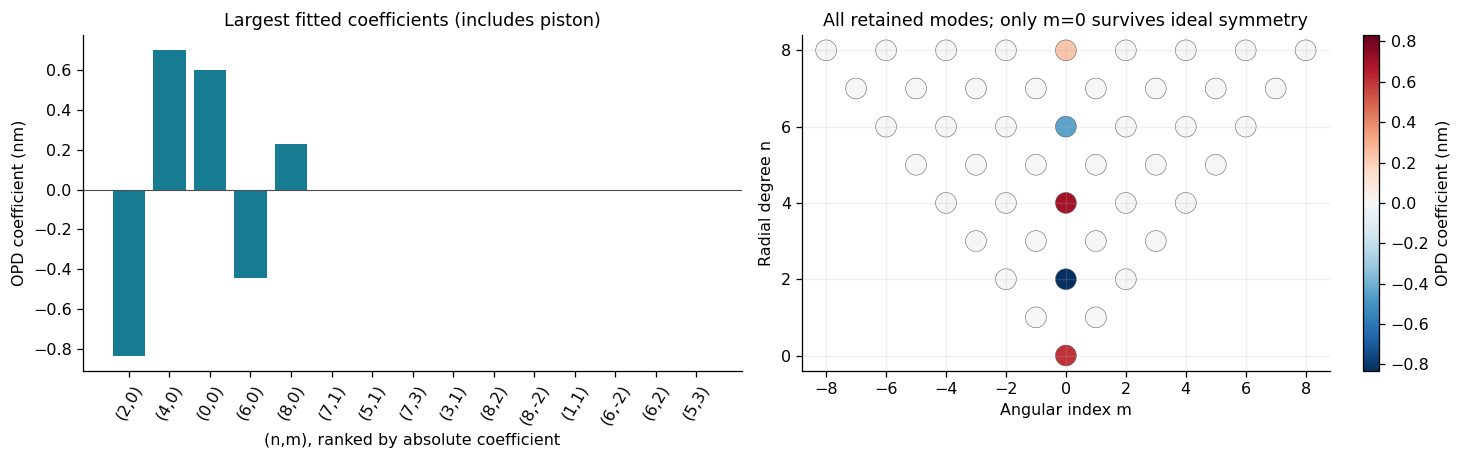

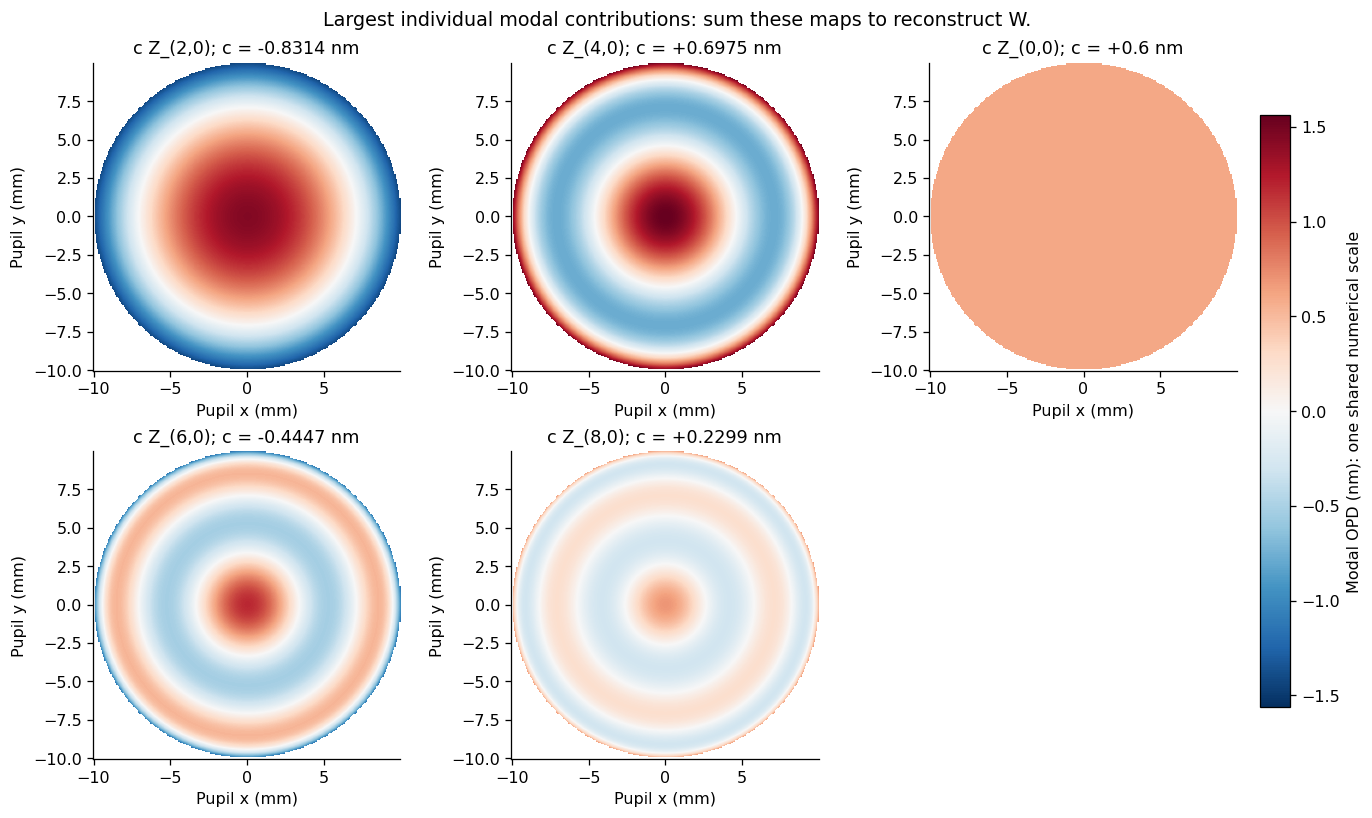

In [9]:
# C09 — All coefficients, a worked projection, and largest modal contributions.
COEFFICIENTS=BASE['coefficients']
with pd.option_context('display.max_rows',None,'display.float_format',lambda x:f'{x:.7g}'):
    display(COEFFICIENTS)
if (2,0) in f['modes'] and P.obscuration_ratio==0:
    j=f['modes'].index((2,0))
    c20_direct=np.dot(f['weights'],f['measured_nm']*f['B'][:,j])
    print(f'Worked projection: c_2^0 = sum(weight * W_measured * Z_2^0) = {c20_direct:+.8g} nm')
for name,make in [('03_zernike_coefficients',plot_coefficients),('04_modal_contributions',plot_modal_contributions)]:
    FIGURES[name]=make(BASE);display(FIGURES[name]);plt.close(FIGURES[name])


## M10 — What does the actual point image look like?

Inspect the common-scale PSFs, cross sections and encircled energy. For a centred circular dent, the image remains rotationally symmetric: the peak and concentric distribution change, with no preferred coma tail, astigmatic axis or placement direction. An offset/elliptical dent changes that symmetry.

The quantitative intensity comparison is

$$\epsilon_I=\frac{\|I_{\rm reconstructed}-I_{\rm true}\|_2}{\|I_{\rm true}\|_2}$$

over the **full FFT array**, not just the displayed crop. The residual image is a signed intensity difference. This compares known simulated wavefronts; it does not infer a unique wavefront from an intensity image.


,on_axis_ratio,sampled_peak_ratio,energy_in_0p61,discrete_total_intensity
case,,,,
Ideal,1.000000,1.000000,0.838064,20.388015
True dent,0.770383,0.770383,0.594294,20.388015
Zernike reconstruction,0.764265,0.764265,0.590581,20.388015


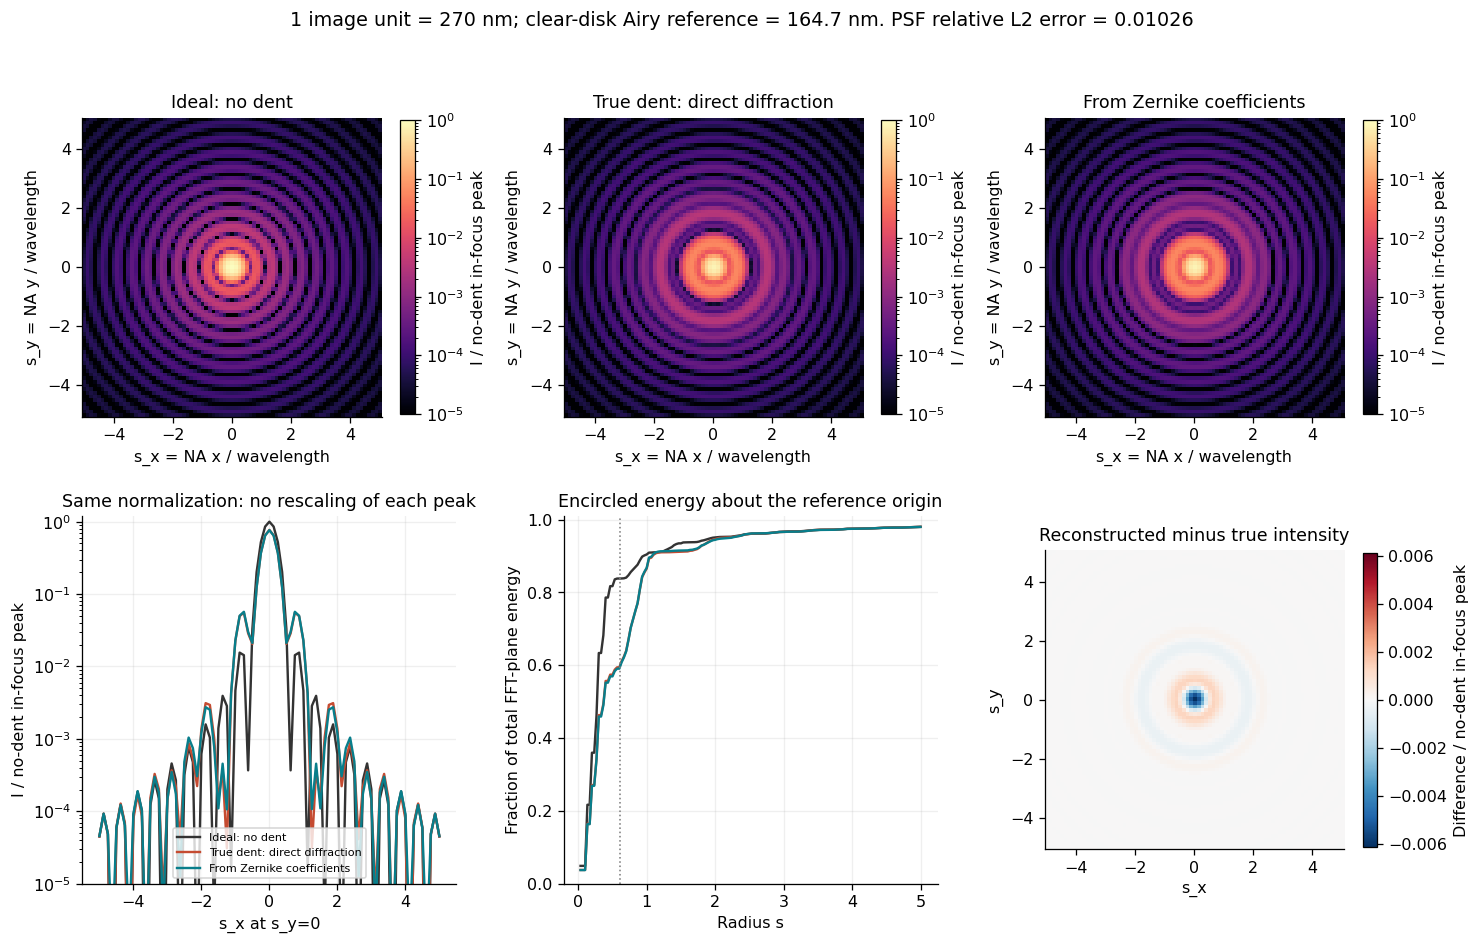

**Readout:** true on-axis intensity is 77.038% of the dent-free in-focus peak. Within radius 0.61 image units, the ideal pupil contains 83.81% of its total energy and the true dent contains 59.43%. Total power is conserved: light has been redistributed. Reconstruction PSF relative L2 error is 1.026%.

In [10]:
# C10 — True PSF versus the PSF reconstructed from Zernike coefficients.
display(BASE['metrics'].round(7))
FIGURES['05_point_images']=plot_psfs(BASE)
display(FIGURES['05_point_images']);plt.close(FIGURES['05_point_images'])

_metrics=BASE['metrics']
display(Markdown(f"**Readout:** true on-axis intensity is {_metrics.loc['True dent','on_axis_ratio']:.3%} of the dent-free in-focus peak. Within radius 0.61 image units, the ideal pupil contains {_metrics.loc['Ideal','energy_in_0p61']:.2%} of its total energy and the true dent contains {_metrics.loc['True dent','energy_in_0p61']:.2%}. Total power is conserved: light has been redistributed. Reconstruction PSF relative L2 error is {BASE['relative_psf_error']:.3%}."))


## M11 — Imaging a simple object

The point pair and three bars show changes in separation and contrast. The ideal image is the diffraction image made by the same system without the dent; the input-object panel is a separate reference. The **input object has its own logarithmic display scale**; all three image panels share one intensity scale. A finite field crops outgoing light, so cropped images are not renormalized to equal flux.

Try <code>scene_kind='two_points'</code> and vary separation; or use <code>'bars'</code> and vary width/gap. Point flux is deposited by interpolation; bars are supersampled within pixels. Sampling remains finite: very narrow features require a convergence check. Physical lengths are obtained by multiplying $s$ by <code>P.image_unit_nm</code>.


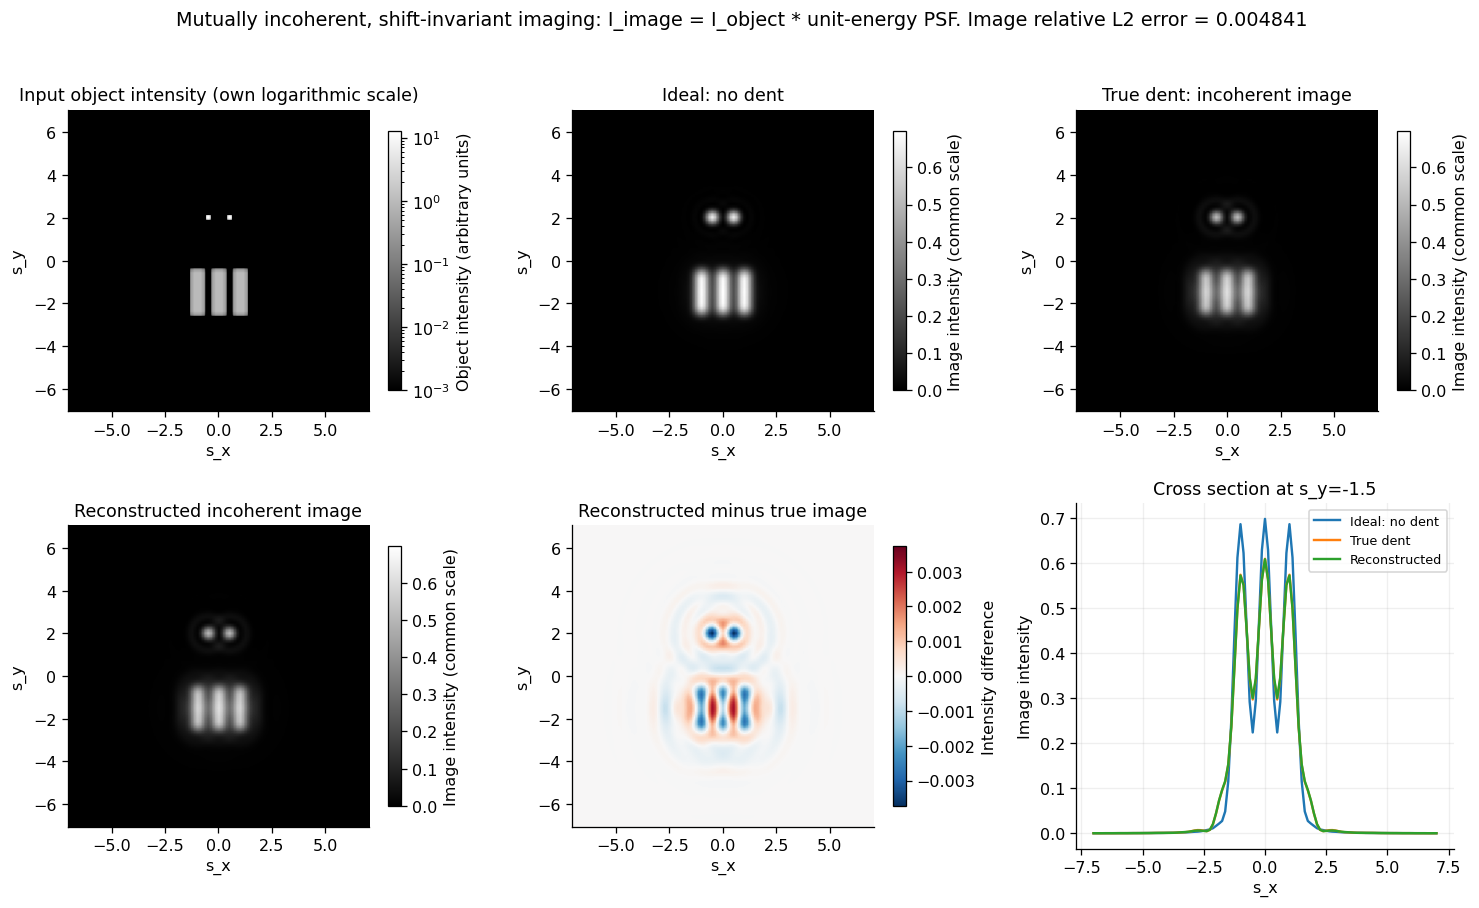

In [11]:
# C11 — Ideal, true and reconstructed images of the same incoherent object.
FIGURES['06_extended_object_images']=plot_scene(BASE)
display(FIGURES['06_extended_object_images']);plt.close(FIGURES['06_extended_object_images'])


## M12 — How many modes are enough?

Refit the same dent at each chosen degree and propagate each reconstruction. The truth and applied focus remain identical across the sweep. Complete noiseless nested fits reduce wavefront RMS monotonically; an image metric such as on-axis intensity need not change monotonically.

The symmetric default needs only $m=0$ modes in exact mathematics, but the default <code>all</code> setting demonstrates that other coefficients vanish. Degree 8 contains 45 real modes; degree 20 contains 231. Restricting to axisymmetric modes saves work only while that symmetry holds. Noise can introduce a residual floor or overfitting.


,n_max,mode_count,residual_rms_nm,residual_rms_waves,variance_explained,psf_relative_L2,on_axis_ratio,sampled_peak_ratio,energy_in_0p61
0,0,1,1.200014,0.088890,0.000000,4.034707e-01,1.000000,1.000000,0.838064
1,2,6,0.865297,0.064096,0.480054,2.360133e-01,0.859151,0.859151,0.756425
2,4,15,0.512020,0.037927,0.817945,6.451575e-02,0.776428,0.776428,0.640146
3,6,28,0.253790,0.018799,0.955272,1.732638e-02,0.759910,0.759910,0.595855
4,8,45,0.107443,0.007959,0.991984,1.026194e-02,0.764265,0.764265,0.590581
5,10,66,0.039518,0.002927,0.998916,3.750717e-03,0.768452,0.768452,0.592582
6,12,91,0.012813,0.000949,0.999886,9.451960e-04,0.769940,0.769940,0.593825
7,16,153,0.000967,0.000072,0.999999,2.737600e-05,0.770373,0.770373,0.594279
8,20,231,0.000050,0.000004,1.000000,5.830000e-07,0.770383,0.770383,0.594293


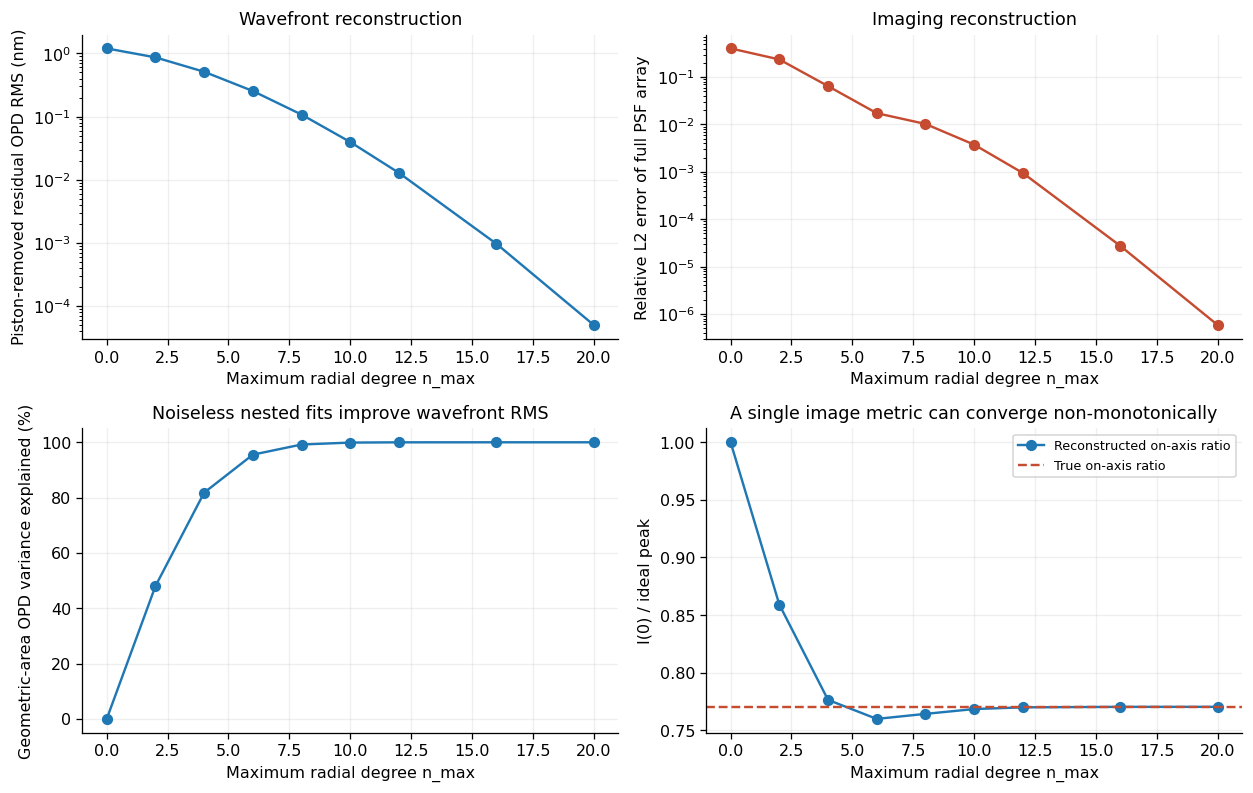

In [12]:
# C12 — EDIT CONVERGENCE_ORDERS in C02 to change the sweep.
CONVERGENCE=convergence_study(P,CONVERGENCE_ORDERS)
display(CONVERGENCE.drop(columns='discrete_total_intensity').round(9))
FIGURES['07_order_convergence']=plot_convergence(CONVERGENCE,BASE)
display(FIGURES['07_order_convergence']);plt.close(FIGURES['07_order_convergence'])


## M13 — Optional diagnostic: can refocusing remove the defect?

A focus change can compensate a quadratic component, but cannot remove a general localized Gaussian profile. This separate illustration adds $dZ_2^0$ to minimize **piston-removed geometric-area RMS** of the actual wavefront:

$$d=-\frac{\operatorname{Cov}(W_{\rm current},Z_2^0)}{\operatorname{Var}(Z_2^0)}.$$

On a clear disk this removes its current defocus coefficient. It is **not** an optimization of peak intensity or object contrast, and uses known simulated truth. No result above is changed. The corresponding paraxial observation-plane shift is $\Delta z=-4\sqrt3\,d/\mathrm{NA}^2$, with $d$ and $\Delta z$ in the same length units. A sufficiently large shift would require revisiting the first-order propagation approximation.


Additional area-RMS-optimal Z_2^0 coefficient (nm): 0.831441004822266


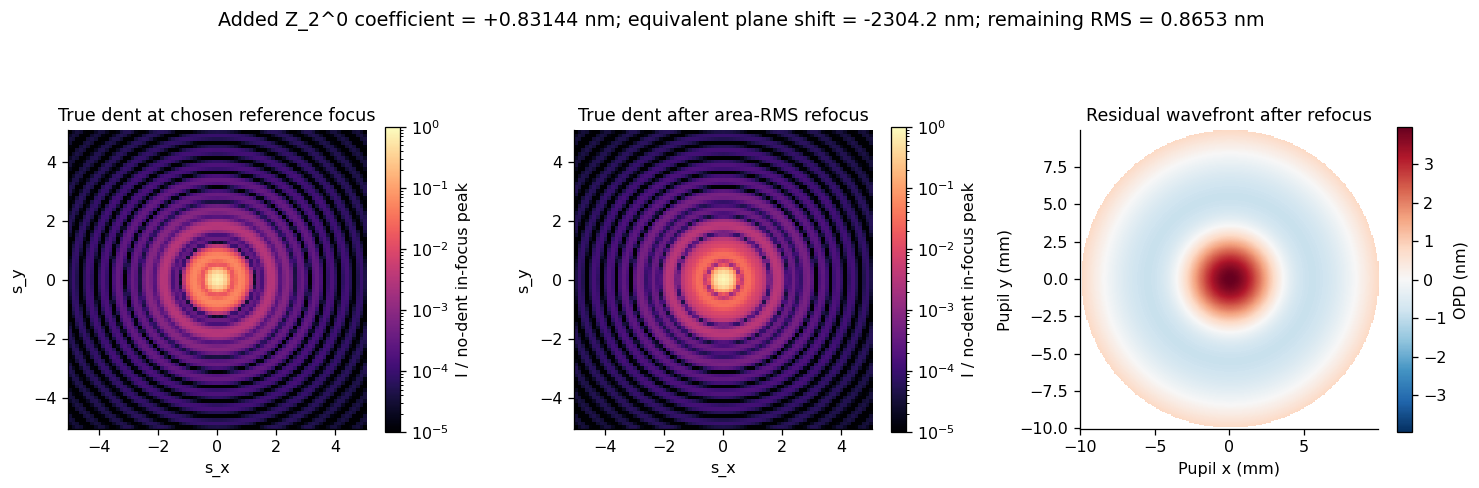

In [13]:
# C13 — Separate refocus diagnostic: does not alter P or BASE.
print('Additional area-RMS-optimal Z_2^0 coefficient (nm):',area_rms_refocus_coefficient(BASE))
FIGURES['08_refocus_diagnostic']=plot_refocus(BASE)
display(FIGURES['08_refocus_diagnostic']);plt.close(FIGURES['08_refocus_diagnostic'])


## M14 — Numerical accountability

Checks use known-mode recovery, analytic Gaussian mean/RMS, independent 1D radial integrals, angular symmetry, variance accounting, piston invariance, the Fourier tilt shift, power conservation, masked-pupil QR recovery, convolution centring, and quadrature refinement. They test physical/numerical invariants independently of whether two plots look similar.

The circular FFT aperture is pixelated: accurate coefficient quadrature does not eliminate imaging discretization. Also increase pupil sampling and padding and verify stability of the metric of interest. Fitting never assumes that the Cartesian FFT pixels form an exactly orthogonal integration grid.


In [14]:
# C14 — Independent checks, including dent-free reference at nonzero focus.
import types
from scipy.integrate import quad
_notebook_model=types.SimpleNamespace(**globals())
def verify_all(output=None,include_widget=True):
    r={}
    p=_notebook_model.Parameters(n_pupil=128,fft_pad=4)
    s=_notebook_model.build_study(p);f=s['fit']; w=f['weights']
    r['gram_max_abs_error']=f['gram_error']; assert r['gram_max_abs_error']<1e-11
    r['weight_sum_error']=abs(w.sum()-1);assert r['weight_sum_error']<1e-14
    n,midx=4,2
    synthetic=1.25*_notebook_model.zernike(n,midx,f['u'],f['v'])-.3*_notebook_model.zernike(2,0,f['u'],f['v'])
    coefficients=f['B'].T@(w*synthetic)
    expected=np.array([1.25 if mode==(4,2) else -.3 if mode==(2,0) else 0 for mode in f['modes']])
    r['known_mode_recovery_nm']=float(np.max(abs(coefficients-expected)));assert r['known_mode_recovery_nm']<1e-11
    amplitude=2*p.depth_nm*np.cos(np.deg2rad(p.incidence_deg));F=p.area_fraction
    mean=amplitude*F*(-np.expm1(-1/F))
    second=amplitude**2*F/2*(-np.expm1(-2/F))
    analytic_rms=np.sqrt(second-mean**2)
    r['gaussian_mean_nm_error']=abs(np.dot(w,f['true_nm'])-mean)
    r['gaussian_rms_nm_error']=abs(f['true_rms_nm']-analytic_rms)
    assert max(r['gaussian_mean_nm_error'],r['gaussian_rms_nm_error'])<1e-11
    independent=[]
    for (n,mm),c in zip(f['modes'],f['coeff_nm']):
        if mm==0:
            exact=amplitude*np.sqrt(n+1)*quad(lambda t:np.exp(-t/F)*_notebook_model.eval_legendre(n//2,2*t-1),0,1,epsabs=1e-12)[0]
            independent.append(abs(c-exact))
    r['independent_radial_integral_coeff_nm_error']=float(max(independent));assert r['independent_radial_integral_coeff_nm_error']<1e-10
    angular=np.array([abs(c) for (n,mm),c in zip(f['modes'],f['coeff_nm']) if mm!=0])
    r['centered_dent_nonradial_coeff_nm_max']=float(angular.max());assert r['centered_dent_nonradial_coeff_nm_max']<1e-12
    variance=f['true_rms_nm']**2
    modal_variance=sum(c*c for mode,c in zip(f['modes'],f['coeff_nm']) if mode!=(0,0))
    r['parseval_residual_variance_nm2_error']=abs(f['residual_rms_nm']**2-(variance-modal_variance))
    assert r['parseval_residual_variance_nm2_error']<1e-10
    # Piston invariance and the DFT shift theorem are independent physical invariants.
    _,piston=_notebook_model.propagate_psf(np.full_like(s['u'],2.73),s['amplitude'],p)
    r['piston_psf_max_abs_error']=float(np.max(abs(piston-s['ideal_psf'])));assert r['piston_psf_max_abs_error']<1e-12
    ds=s['s'][1]-s['s'][0]; pixel_shift=3
    _,tilt=_notebook_model.propagate_psf(p.wavelength_nm*pixel_shift*ds*s['u'],s['amplitude'],p)
    r['positive_tilt_roll_max_abs_error']=float(np.max(abs(tilt-np.roll(s['ideal_psf'],pixel_shift,axis=1))))
    assert r['positive_tilt_roll_max_abs_error']<1e-12
    r['phase_only_total_energy_relative_error']=max(abs(s[key].sum()/s['ideal_psf'].sum()-1) for key in ['true_psf','recon_psf'])
    assert r['phase_only_total_energy_relative_error']<1e-12
    perfect=_notebook_model.build_study(replace(p,depth_nm=0))
    r['zero_dent_psf_error']=float(np.max(abs(perfect['recon_psf']-perfect['ideal_psf'])));assert r['zero_dent_psf_error']<1e-14
    # The ideal comparison removes the dent ONLY, including at nonzero selected focus.
    no_dent_defocused=_notebook_model.build_study(replace(p,depth_nm=0,added_defocus_nm=.6))
    r['no_dent_same_focus_psf_error']=float(max(np.max(abs(no_dent_defocused[k]-no_dent_defocused['ideal_psf'])) for k in ('true_psf','recon_psf')))
    assert r['no_dent_same_focus_psf_error']<1e-12
    assert np.max(abs(no_dent_defocused['ideal_psf']-perfect['ideal_psf']))>1e-3
    offset=_notebook_model.fit_wavefront(replace(p,center_u=.35))
    cx=offset['coeff_nm'][offset['modes'].index((1,1))]
    cy=offset['coeff_nm'][offset['modes'].index((1,-1))]
    assert abs(cx)>.05 and abs(cy)<1e-12
    r['offset_x_tilt_nm']=float(cx);r['offset_y_tilt_nm']=float(cy)
    # An annular support does not preserve disk orthogonality: recover a known polynomial by QR.
    ann=_notebook_model.polar_basis(8,'all',.3,64,128);aw=ann['weights'];AB=ann['B']
    target=.7*_notebook_model.zernike(4,0,ann['u'],ann['v'])-.2*_notebook_model.zernike(2,2,ann['u'],ann['v'])
    recovered,_,rank,_=_notebook_model.linalg.lstsq(np.sqrt(aw)[:,None]*AB,np.sqrt(aw)*target,lapack_driver='gelsy')
    ex=np.array([.7 if mode==(4,0) else -.2 if mode==(2,2) else 0 for mode in ann['modes']])
    r['annular_QR_recovery_nm_error']=float(np.max(abs(recovered-ex)));assert r['annular_QR_recovery_nm_error']<1e-10
    r['annular_gram_nonidentity']=float(np.max(abs(ann['G']-np.eye(len(ex)))));assert r['annular_gram_nonidentity']>.01
    # Check even-sized kernel centering in the extended-object calculation.
    obj=np.zeros((33,33));obj[16,16]=1
    im=_notebook_model.incoherent_image(obj,s['ideal_psf']);center=len(s['s'])//2
    expected=s['ideal_psf'][center-16:center+17,center-16:center+17]/s['ideal_psf'].sum()
    r['delta_object_convolution_alignment_error']=float(np.max(abs(im-expected)));assert r['delta_object_convolution_alignment_error']<1e-12
    conv=_notebook_model.convergence_study(p,orders=(0,2,4,8,12,16,20))
    assert np.all(np.diff(conv.residual_rms_nm)<=1e-10)
    r['n20_residual_nm']=float(conv.iloc[-1].residual_rms_nm);assert r['n20_residual_nm']<1e-4
    r['n20_psf_relative_L2']=float(conv.iloc[-1].psf_relative_L2);assert r['n20_psf_relative_L2']<1e-6
    # Independent quadrature refinement, including an asymmetric/elliptical dent.
    q=replace(p,center_u=.2,center_v=-.1,aspect_ratio=1.7,orientation_deg=31)
    fq=_notebook_model.fit_wavefront(q);fine=_notebook_model.fit_wavefront(replace(q,quad_radial=96,quad_angular=192))
    r['quadrature_refinement_coeff_nm_error']=float(np.max(abs(fq['coeff_nm']-fine['coeff_nm'])));assert r['quadrature_refinement_coeff_nm_error']<1e-9
    noisy=replace(p,noise_rms_nm=.1,seed=123)
    r['noise_seed_repeat_error']=float(np.max(abs(_notebook_model.fit_wavefront(noisy)['coeff_nm']-_notebook_model.fit_wavefront(noisy)['coeff_nm'])));assert r['noise_seed_repeat_error']==0
    # Imaging sampling check: on-axis diffraction also has an independent disk integral.
    exact_axis=abs(np.dot(w,np.exp(2j*np.pi*f['true_nm']/p.wavelength_nm)))**2
    grid_results=[]
    for ng in (128,256,384):
        sg=_notebook_model.build_study(replace(p,n_pupil=ng))
        value=float(sg['metrics'].loc['True dent','on_axis_ratio'])
        grid_results.append({'pupil_pixels':ng,'on_axis_ratio':value,'absolute_error':abs(value-exact_axis)})
    r['independent_on_axis_ratio']=float(exact_axis)
    r['image_grid_refinement']=grid_results
    assert grid_results[-1]['absolute_error']<grid_results[0]['absolute_error']
    assert grid_results[1]['absolute_error']<3e-4
    airy_study=_notebook_model.build_study(replace(p,n_pupil=256))
    axis=airy_study['s'];sel=(axis>0)&(axis<=3)
    exact_airy=(2*_notebook_model.j1(2*np.pi*axis[sel])/(2*np.pi*axis[sel]))**2
    r['ideal_airy_cut_max_abs_error']=float(np.max(abs(airy_study['ideal_psf'][len(axis)//2,sel]-exact_airy)))
    assert r['ideal_airy_cut_max_abs_error']<2e-3
    _,coarse=_notebook_model.propagate_psf(s['actual_nm'],s['amplitude'],replace(p,fft_pad=2))
    r['zero_padding_common_samples_max_error']=float(np.max(abs(coarse-s['true_psf'][::2,::2])))
    assert r['zero_padding_common_samples_max_error']<1e-12
    if include_widget:
        dash=_notebook_model.make_dashboard(p,render=False)
        dash['controls']['center_u'].value=.25;dash['controls']['n_max'].value=6
        dash['button'].click()
        assert dash['state']['error'] is None and dash['state']['study']['p'].center_u==.25
        assert dash['state']['study']['p'].n_max==6
        r['ipywidgets_button_callback']='PASS (Python backend; no frontend browser automation)'
    r['status']='PASS'
    if output:
        Path(output).write_text(json.dumps(r,indent=2),encoding='utf-8')
    return r


CHECK_RESULTS=verify_all(CHECKS_DIR/'verification.json',include_widget=False)
display(pd.DataFrame([CHECK_RESULTS]).T.rename(columns={0:'Check result'}))
display(pd.DataFrame(CHECK_RESULTS['image_grid_refinement']))


,Check result
gram_max_abs_error,0.0
weight_sum_error,0.0
known_mode_recovery_nm,0.0
gaussian_mean_nm_error,0.0
gaussian_rms_nm_error,0.0
independent_radial_integral_coeff_nm_error,0.0
centered_dent_nonradial_coeff_nm_max,0.0
parseval_residual_variance_nm2_error,0.0
piston_psf_max_abs_error,0.0
positive_tilt_roll_max_abs_error,0.0


,pupil_pixels,on_axis_ratio,absolute_error
0,128,0.770291,0.000232
1,256,0.770383,0.000140
2,384,0.770473,0.000050


## M15 — Live exploration controls

Change values and click **Compute selected case**. This updates OPD maps, PSFs, object images, image metrics and the largest coefficients. Changes are applied together, so dragging does not repeatedly launch expensive FFTs. Invalid combinations display a parameter message.

The dashboard inherits numerical, aperture and object settings from C02; edit C02 for those advanced settings. Baseline results remain available. To save a successful interactive case later, run <code>export_study(DASHBOARD['state']['study'], directory=PROJECT_DIR/'interactive_results')</code> after C16 has defined the export function.


In [15]:
# C15 — Live controls: active kernel and widget-enabled frontend required.
def make_dashboard(base_parameters,render=True):
    """Button-driven widgets; control changes never silently overwrite the base study."""
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    style={'description_width':'155px'}; layout=widgets.Layout(width='370px')
    def fs(description,value,minimum,maximum,step):
        return widgets.FloatSlider(description=description,value=value,min=minimum,max=maximum,step=step,
                                   continuous_update=False,readout_format='.3g',style=style,layout=layout)
    p=base_parameters
    controls={
      'depth_nm':fs('Dent depth (nm)',p.depth_nm,-max(10.,abs(p.depth_nm)),max(10.,abs(p.depth_nm)),.1),
      'area_fraction':fs('1/e area fraction',p.area_fraction,.005,.8,.005),
      'center_u':fs('Centre u / radius',p.center_u,-1,1,.05),
      'center_v':fs('Centre v / radius',p.center_v,-1,1,.05),
      'aspect_ratio':fs('Gaussian aspect ratio',p.aspect_ratio,1,4,.1),
      'orientation_deg':fs('Ellipse rotation (deg)',p.orientation_deg,-180,180,5),
      'added_defocus_nm':fs('Added Z20 (nm OPD)',p.added_defocus_nm,-max(5.,abs(p.added_defocus_nm)),max(5.,abs(p.added_defocus_nm)),.1),
      'noise_rms_nm':fs('OPD noise RMS (nm)',p.noise_rms_nm,0,max(2.,p.noise_rms_nm),.01),
      'n_max':widgets.IntSlider(description='Maximum degree n',value=p.n_max,min=0,max=24,continuous_update=False,style=style,layout=layout),
      'wavelength_nm':widgets.FloatLogSlider(description='Wavelength (nm)',value=p.wavelength_nm,base=10,min=np.log10(min(1.,p.wavelength_nm)),max=np.log10(max(1000.,p.wavelength_nm)),step=.02,continuous_update=False,style=style,layout=layout),
      'fit_family':widgets.Dropdown(description='Fitted modes',value=p.fit_family,options=['all','axisymmetric'],style=style,layout=layout)}
    button=widgets.Button(description='Compute selected case',button_style='primary',icon='play')
    status=widgets.HTML('<i>Change controls, then click Compute. Baseline results above remain available.</i>')
    output=widgets.Output(); state={'study':None,'error':None}
    def compute(_):
        button.disabled=True;status.value='<b>Computing...</b>';state['error']=None
        try:
            q=replace(p,**{name:c.value for name,c in controls.items()})
            result=build_study(q);state['study']=result
            if render:
                with output:
                    clear_output(wait=True)
                    display(result['metrics'].round(6))
                    display(result['coefficients'].sort_values('coefficient_nm',key=abs,ascending=False).head(12))
                    for make in (plot_wavefronts,plot_psfs,plot_scene):
                        fig=make(result);display(fig);plt.close(fig)
            status.value=(f'<b>Complete:</b> {len(result["fit"]["modes"])} modes; '
                          f'residual RMS {result["fit"]["residual_rms_nm"]:.5g} nm; '
                          f'PSF relative L2 error {result["relative_psf_error"]:.5g}.')
        except Exception as exc:
            state['error']=str(exc);status.value='<b>Parameter error:</b> '+str(exc)
        finally:button.disabled=False
    button.on_click(compute)
    left=widgets.VBox([controls[k] for k in ['depth_nm','area_fraction','center_u','center_v','aspect_ratio','orientation_deg']])
    right=widgets.VBox([controls[k] for k in ['n_max','fit_family','wavelength_nm','added_defocus_nm','noise_rms_nm']])
    ui=widgets.VBox([widgets.HBox([left,right],layout=widgets.Layout(flex_flow='row wrap')),button,status,output])
    return {'ui':ui,'controls':controls,'button':button,'state':state,'compute':compute}

DASHBOARD=make_dashboard(P)
display(DASHBOARD['ui'])
# Check callback wiring separately, without replacing the displayed dashboard state.
_test_ui=make_dashboard(Parameters(n_pupil=128,fft_pad=2),render=False)
_test_ui['controls']['center_u'].value=.25
_test_ui['controls']['n_max'].value=6
_test_ui['button'].click()
assert _test_ui['state']['error'] is None, _test_ui['state']['error']
assert _test_ui['state']['study']['p'].center_u==.25
print('Widget computation callback checked. Displayed controls are ready.')


Widget computation callback checked. Displayed controls are ready.


## M16 — Save data, figures and provenance

Exports contain parameters, every coefficient in nm and waves, full-array image metrics, convergence data, actual/reconstructed OPD arrays, cropped PSF arrays with coordinates, and PNG/PDF versions of all eight figures. Dependency versions, conventions and SHA-256 hashes are recorded. Scalar metrics use full FFT arrays even though exported display images are cropped.

With <code>EXPORT_FILES=True</code>, this cell overwrites named **baseline** files in the results folder; choose another directory to retain separate cases. Interactive cases are saved only by the explicit command above. The notebook includes its mathematical/plotting code; the adjacent Python module and verifier also allow script-based checks.


In [16]:
# C16 — Reproducible export; change directory to retain multiple cases.
def export_study(study,convergence=None,figures=None,directory='results'):
    import importlib.metadata as metadata
    path=Path(directory);path.mkdir(parents=True,exist_ok=True)
    p=study['p']
    (path/'parameters.json').write_text(json.dumps(asdict(p),indent=2),encoding='utf-8')
    study['coefficients'].to_csv(path/'zernike_coefficients.csv',index=False)
    study['metrics'].to_csv(path/'image_metrics.csv')
    if convergence is not None:convergence.to_csv(path/'convergence.csv',index=False)
    crop,sc=_psf_crop(study)
    np.savez_compressed(path/'reconstruction_arrays.npz',u=study['u'],v=study['v'],
                        support=study['support'],amplitude=study['amplitude'],
                        height_nm=study['height_nm'],true_wavefront_nm=study['actual_nm'],
                        reconstructed_wavefront_nm=study['reconstructed_nm'],
                        s_crop=sc,ideal_psf_crop=study['ideal_psf'][np.ix_(crop,crop)],
                        true_psf_crop=study['true_psf'][np.ix_(crop,crop)],
                        reconstructed_psf_crop=study['recon_psf'][np.ix_(crop,crop)])
    for name,fig in (figures or {}).items():
        fig.savefig(path/(name+'.png'),bbox_inches='tight')
        fig.savefig(path/(name+'.pdf'),bbox_inches='tight')
    versions={name:metadata.version(name) for name in ['numpy','scipy','matplotlib','pandas','ipywidgets','nbformat','nbclient','ipykernel']}
    provenance={'python':sys.version,'platform':platform.platform(),'versions':versions,
                'normalization':'Zernike full-disk unit mean square; m>0 cosine, m<0 sine',
                'height_to_opd':'W_nm = -2*h_nm*cos(incidence_deg); positive h toward incident space',
                'pupil_model':'Scalar paraxial; fixed mapped pupil; phase-only defect; uniform coating',
                'psf_normalization':'Common dent-free in-focus peak; no per-image peak normalization',
                'ideal_comparison':'Dent removed; identical pupil, amplitude, wavelength and added defocus',
                'object_model':'Spatially incoherent, shift-invariant intensity convolution',
                'fit_method':study['fit']['method'],
                'fit_gram_error':study['fit']['gram_error'],
                'fit_condition_design':study['fit']['condition_design'],
                'source':'Local aberration_budget_textbook.pdf Chapter 7; 27 Oct teaching model',
                'array_export':'PSF views are cropped; scalar metrics use the full FFT plane.'}
    (path/'provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
    files=[]
    for f in sorted(path.iterdir()):
        if f.is_file() and f.name!='manifest.json':
            data=f.read_bytes();files.append({'path':f.name,'bytes':len(data),'sha256':hashlib.sha256(data).hexdigest()})
    (path/'manifest.json').write_text(json.dumps(files,indent=2),encoding='utf-8')
    print(f'Exported {len(files)} files to {path.resolve()}')
    return path

if EXPORT_FILES:
    EXPORTED_TO=export_study(BASE,CONVERGENCE,FIGURES,RESULTS_DIR)
else:
    print('No files exported: EXPORT_FILES=False.')


Exported 22 files to C:\Users\fxl04\Desktop\Prof. Wong Grp Papers\Discussion Series\27 Oct\results


## M17 — Suggested experiments

1. **Remove the defect:** set <code>depth_nm=0</code>; the ideal, true and reconstructed PSFs should coincide.
2. **Change optical sensitivity:** change 13.5 nm to 550 nm while keeping the same 3 nm dent. Geometry is unchanged; phase in waves is much smaller.
3. **Narrow the dent:** reduce area fraction from 0.10 to 0.02. Increase order and pupil resolution; a localized feature needs higher radial structure.
4. **Break rotational symmetry:** set <code>center_u=0.35</code>. Nonzero angular modes appear. Compare all modes with the axisymmetric-only restriction.
5. **Make an elliptical dent:** set aspect ratio to 2 and rotate its axes. Angular families appear while nominal contour area remains fixed.
6. **Explore focus:** vary added defocus and compare C13. Lower pupil RMS does not guarantee the optimum of every image metric.
7. **Add measurement noise:** try 0.1 nm OPD RMS with a fixed seed. Higher orders can eventually fit noise.
8. **Change the pupil:** try an obscuration ratio of 0.3 or edge amplitude of 0.5. Inspect fit method/Gram matrix and compare to the matching ideal pupil.
9. **Refine numerics independently:** more quadrature nodes test coefficients; more pupil pixels test the sampled physical pupil; more FFT padding tests image sampling.

This is a **forward modelling exercise** using the known/unwrapped wavefront. One intensity image generally does not determine a unique wavefront: piston is invisible, and other degeneracies remain. Zernike orthogonality does not make modal image-intensity effects additive or uniquely invertible.


## M18 — Sources and scope

- Local [aberration-budget textbook](../../aberration%20budget%20paper/aberration_budget_textbook.pdf), Chapter 7, *Zernike polynomials from the beginning*: general definition, coefficient recovery, RMS, and masked-pupil fitting. Chapter 6 supplies imaging/focus context. The normalized convention is explicit above.
- [NIST DLMF §18.5](https://dlmf.nist.gov/18.5), Jacobi/Legendre representations, cross-checks the radial-polynomial convention.
- [Ansys Optics: surface irregularity using a phase surface](https://optics.ansys.com/hc/en-us/articles/43071104496147-Tolerancing-surface-irregularity-using-a-phase-surface), supports distinguishing surface error from reflected wavefront error. M04 derives the signed path relation for the geometry used here.
- [ipywidgets: Using Interact](https://ipywidgets.readthedocs.io/en/stable/examples/Using%20Interact.html), documents kernel-backed controls. This notebook uses an explicit compute button.

This is an original teaching simulation, not a reconstruction of the paper's unspecified single-index mode sequence or a full EUV multilayer/mask model. Its numerical comparisons apply to the declared scalar pupil model.
